In [5]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Scanpy version:", sc.__version__)
print("AnnData version:", ad.__version__)
print("Pandas version:", pd.__version__)

print("\nEnvironment ready!")

Scanpy version: 1.11.5
AnnData version: 0.12.19
Pandas version: 2.3.3

Environment ready!


/tmp/ipykernel_259845/2511177953.py:7: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy version:", sc.__version__)
/tmp/ipykernel_259845/2511177953.py:8: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print("AnnData version:", ad.__version__)


## 1. Inspect raw gene-expression data

Before combining samples, inspect one raw-count matrix to determine its
orientation, dimensions, gene identifiers, and cell identifiers.

In [6]:
from pathlib import Path

# Path from the notebook to our raw count matrices
data_dir = Path("../data/raw_counts")

# Find all raw-count files
count_files = sorted(data_dir.glob("*.rawCounts.csv.gz"))

print("Number of raw-count files:", len(count_files))
print("\nFirst 5 files:")

for file in count_files[:5]:
    print(file.name)

Number of raw-count files: 38

First 5 files:
GSM5264634_2_t4_CSF_uns_5pGEX.rawCounts.csv.gz
GSM5264635_2_t4_PB_uns_5pGEX.rawCounts.csv.gz
GSM5264636_3_t2_CSF_uns_5pGEX.rawCounts.csv.gz
GSM5264637_3_t2_PB_uns_5pGEX.rawCounts.csv.gz
GSM5264638_5_t1_PB_uns_5pGEX.rawCounts.csv.gz


In [7]:
first_file = count_files[0]

print("Inspecting:")
print(first_file.name)

df_test = pd.read_csv(first_file, compression="gzip")

print("\nShape:", df_test.shape)
display(df_test.head())

Inspecting:
GSM5264634_2_t4_CSF_uns_5pGEX.rawCounts.csv.gz

Shape: (33538, 485)


,AAACGGGCAAATTGCC-2_t4_CSF_uns_5pGEX,AAAGATGCATCAGTCA-2_t4_CSF_uns_5pGEX,AAAGCAATCAAAGTAG-2_t4_CSF_uns_5pGEX,AAAGCAATCCGTCATC-2_t4_CSF_uns_5pGEX,AAATGCCGTTCCGGCA-2_t4_CSF_uns_5pGEX,AACCGCGCACATTAGC-2_t4_CSF_uns_5pGEX,AACCGCGGTACAGTTC-2_t4_CSF_uns_5pGEX,AACGTTGAGGCCGAAT-2_t4_CSF_uns_5pGEX,AACTCAGAGCCATCGC-2_t4_CSF_uns_5pGEX,AACTCAGCATCAGTCA-2_t4_CSF_uns_5pGEX,...,TTGCCGTTCCTTGACC-2_t4_CSF_uns_5pGEX,TTGCGTCAGAGTTGGC-2_t4_CSF_uns_5pGEX,TTGGAACAGATACACA-2_t4_CSF_uns_5pGEX,TTGGAACTCATCGCTC-2_t4_CSF_uns_5pGEX,TTGGCAAGTGAGCGAT-2_t4_CSF_uns_5pGEX,TTTATGCGTGACGCCT-2_t4_CSF_uns_5pGEX,TTTCCTCAGCAGGTCA-2_t4_CSF_uns_5pGEX,TTTGCGCTCTAACGGT-2_t4_CSF_uns_5pGEX,TTTGCGCTCTTAGCCC-2_t4_CSF_uns_5pGEX,TTTGTCATCAACGGGA-2_t4_CSF_uns_5pGEX
MIR1302-2HG,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
FAM138A,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
OR4F5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AL627309.1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AL627309.3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
#Build metadata from the filenames

import re

records = []

for file in count_files:
    name = file.name

    # Remove the ending
    base = name.replace(".rawCounts.csv.gz", "")

    # Split filename into components
    parts = base.split("_")

    records.append({
        "file": name,
        "GSM": parts[0],
        "donor": parts[1],
        "timepoint": parts[2],
        "compartment": parts[3],
        "subset": parts[4],
        "library": parts[5]
    })

metadata = pd.DataFrame(records)

display(metadata.head(10))

,file,GSM,donor,timepoint,compartment,subset,library
0,GSM5264634_2_t4_CSF_uns_5pGEX.rawCounts.csv.gz,GSM5264634,2,t4,CSF,uns,5pGEX
1,GSM5264635_2_t4_PB_uns_5pGEX.rawCounts.csv.gz,GSM5264635,2,t4,PB,uns,5pGEX
2,GSM5264636_3_t2_CSF_uns_5pGEX.rawCounts.csv.gz,GSM5264636,3,t2,CSF,uns,5pGEX
3,GSM5264637_3_t2_PB_uns_5pGEX.rawCounts.csv.gz,GSM5264637,3,t2,PB,uns,5pGEX
4,GSM5264638_5_t1_PB_uns_5pGEX.rawCounts.csv.gz,GSM5264638,5,t1,PB,uns,5pGEX
5,GSM5264639_6_t1_CSF_uns_5pGEX.rawCounts.csv.gz,GSM5264639,6,t1,CSF,uns,5pGEX
6,GSM5264640_6_t1_PB_uns_5pGEX.rawCounts.csv.gz,GSM5264640,6,t1,PB,uns,5pGEX
7,GSM5264641_7_t1_CSF_uns_5pGEX.rawCounts.csv.gz,GSM5264641,7,t1,CSF,uns,5pGEX
8,GSM5264642_7_t1_PB_uns_5pGEX.rawCounts.csv.gz,GSM5264642,7,t1,PB,uns,5pGEX
9,GSM5264643_8_t1_CSF_uns_5pGEX.rawCounts.csv.gz,GSM5264643,8,t1,CSF,uns,5pGEX


## 2. Add clinical sample metadata

The filenames provide technical information such as donor, time point,
compartment, and library type. Disease status must be obtained from the
official GEO sample metadata rather than inferred from the filename.

In [9]:
donors = sorted(metadata["donor"].unique(), key=int)

print("Number of unique donors:", len(donors))
print("Donors:", donors)
print(metadata.groupby(["donor", "compartment"]).size())

Number of unique donors: 19
Donors: ['2', '3', '5', '6', '7', '8', '9', '10', '16', '18', '21', '22', '24', '25', '27', '28', '29', '31', '32']
donor  compartment
10     CSF            1
       PB             1
16     CSF            1
       PB             1
18     CSF            1
       PB             1
2      CSF            1
       PB             1
21     CSF            1
       PB             1
22     CSF            1
       PB             1
24     CSF            1
       PB             1
25     CSF            1
       PB             1
27     CSF            1
       PB             1
28     CSF            1
       PB             1
29     CSF            1
       PB             1
3      CSF            1
       PB             1
31     CSF            1
       PB             2
32     CSF            1
       PB             1
5      PB             1
6      CSF            1
       PB             1
7      CSF            1
       PB             1
8      CSF            1
       PB            

In [18]:
# Show the unique donors that need clinical disease labels

donors_to_label = (
    metadata[["donor"]]
    .drop_duplicates()
    .sort_values("donor", key=lambda x: x.astype(int))
    .reset_index(drop=True)
)

display(donors_to_label)

print("Number of donors:", len(donors_to_label))

,donor
0,2
1,3
2,5
3,6
4,7
5,8
6,9
7,10
8,16
9,18


Number of donors: 19


Current folder:
/home/operation/github/single-cell-disease-pipeline/notebooks

Available .h5ad files:
adata_after_qc_doublets.h5ad
adata_annotated.h5ad
adata_after_qc.h5ad


In [21]:
# ============================================================
# Re-create donor ↔ GSM lookup
# ============================================================
# This makes the following analysis reproducible after
# restarting the Jupyter kernel.
# ============================================================

required_columns = ["donor", "GSM"]

missing_columns = [
    col for col in required_columns
    if col not in adata.obs.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required metadata columns: {missing_columns}"
    )

donor_gsm = (
    adata.obs[["donor", "GSM"]]
    .drop_duplicates()
    .sort_values(["donor", "GSM"])
    .reset_index(drop=True)
)

print("Donor-GSM combinations:")
print(donor_gsm)

print("\nNumber of combinations:", len(donor_gsm))

NameError: name 'adata' is not defined

In [12]:
# Retrieve disease status and subject ID for each donor from GEO sample metadata

import urllib.request
import re
import time


status_records = []

for _, row in donor_gsm.iterrows():

    donor = row["donor"]
    gsm = row["GSM"]

    url = (
        "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi"
        f"?acc={gsm}&targ=self&form=text&view=full"
    )

    with urllib.request.urlopen(url) as response:
        geo_text = response.read().decode("utf-8")

    # Extract disease status
    status_match = re.search(
        r"subject status:\s*(.+)",
        geo_text,
        flags=re.IGNORECASE
    )

    # Extract subject ID
    subject_match = re.search(
        r"subject id:\s*(.+)",
        geo_text,
        flags=re.IGNORECASE
    )

    disease_status = (
        status_match.group(1).strip()
        if status_match else None
    )

    subject_id = (
        subject_match.group(1).strip()
        if subject_match else None
    )

    status_records.append({
        "donor": donor,
        "GSM": gsm,
        "subject_id": subject_id,
        "disease_status": disease_status
    })

    time.sleep(0.3)

clinical_metadata = pd.DataFrame(status_records)

display(clinical_metadata)

NameError: name 'donor_gsm' is not defined

In [13]:
# Add official GEO disease status to the sample metadata

status_map = clinical_metadata.set_index("donor")["disease_status"]

metadata["disease_status"] = metadata["donor"].map(status_map)

display(
    metadata[
        ["GSM", "donor", "timepoint",
         "compartment", "library", "disease_status"]
    ]
)

NameError: name 'clinical_metadata' is not defined

In [ ]:
# Check disease-status assignment

print("Missing disease status:",
      metadata["disease_status"].isna().sum())

print("\nNumber of samples by disease status:")
print(metadata["disease_status"].value_counts())

print("\nNumber of donors by disease status:")
print(
    metadata[["donor", "disease_status"]]
    .drop_duplicates()
    ["disease_status"]
    .value_counts()
)

KeyError: 'disease_status'

In [ ]:
# Inspect the structure of one raw count matrix before creating AnnData

first_file = count_files[0]

df_test = pd.read_csv(
    first_file,
    compression="gzip"
)

print("File:", first_file.name)
print("Shape:", df_test.shape)

print("\nFirst 5 column names:")
print(df_test.columns[:5].tolist())

print("\nFirst 5 index values:")
print(df_test.index[:5].tolist())

print("\nFirst 5 values of the first column:")
print(df_test.iloc[:5, 0].tolist())

display(df_test.iloc[:5, :5])

File: GSM5264634_2_t4_CSF_uns_5pGEX.rawCounts.csv.gz
Shape: (33538, 485)

First 5 column names:
['AAACGGGCAAATTGCC-2_t4_CSF_uns_5pGEX', 'AAAGATGCATCAGTCA-2_t4_CSF_uns_5pGEX', 'AAAGCAATCAAAGTAG-2_t4_CSF_uns_5pGEX', 'AAAGCAATCCGTCATC-2_t4_CSF_uns_5pGEX', 'AAATGCCGTTCCGGCA-2_t4_CSF_uns_5pGEX']

First 5 index values:
['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3']

First 5 values of the first column:
[0, 0, 0, 0, 0]


,AAACGGGCAAATTGCC-2_t4_CSF_uns_5pGEX,AAAGATGCATCAGTCA-2_t4_CSF_uns_5pGEX,AAAGCAATCAAAGTAG-2_t4_CSF_uns_5pGEX,AAAGCAATCCGTCATC-2_t4_CSF_uns_5pGEX,AAATGCCGTTCCGGCA-2_t4_CSF_uns_5pGEX
MIR1302-2HG,0,0,0,0,0
FAM138A,0,0,0,0,0
OR4F5,0,0,0,0,0
AL627309.1,0,0,0,0,0
AL627309.3,0,0,0,0,0


In [ ]:
# Convert one count matrix to AnnData format

from scipy import sparse

# Transpose: genes × cells -> cells × genes
counts = df_test.T

# Convert the count matrix to sparse format
X = sparse.csr_matrix(counts.values)

# Create AnnData object
adata_test = ad.AnnData(X=X)

# Add cell barcodes
adata_test.obs_names = counts.index.astype(str)

# Add gene names
adata_test.var_names = counts.columns.astype(str)

print(adata_test)
print("\nNumber of cells:", adata_test.n_obs)
print("Number of genes:", adata_test.n_vars)

print("\nFirst 5 cells:")
print(adata_test.obs_names[:5].tolist())

print("\nFirst 5 genes:")
print(adata_test.var_names[:5].tolist())

AnnData object with n_obs × n_vars = 485 × 33538

Number of cells: 485
Number of genes: 33538

First 5 cells:
['AAACGGGCAAATTGCC-2_t4_CSF_uns_5pGEX', 'AAAGATGCATCAGTCA-2_t4_CSF_uns_5pGEX', 'AAAGCAATCAAAGTAG-2_t4_CSF_uns_5pGEX', 'AAAGCAATCCGTCATC-2_t4_CSF_uns_5pGEX', 'AAATGCCGTTCCGGCA-2_t4_CSF_uns_5pGEX']

First 5 genes:
['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3']


In [ ]:
# Add sample-level metadata to the cells in the AnnData object

sample_info = metadata.loc[
    metadata["GSM"] == "GSM5264634"
].iloc[0]

adata_test.obs["GSM"] = sample_info["GSM"]
adata_test.obs["donor"] = sample_info["donor"]
adata_test.obs["timepoint"] = sample_info["timepoint"]
adata_test.obs["compartment"] = sample_info["compartment"]
adata_test.obs["subset"] = sample_info["subset"]
adata_test.obs["library"] = sample_info["library"]
adata_test.obs["disease_status"] = sample_info["disease_status"]

display(adata_test.obs.head())

KeyError: 'disease_status'

In [ ]:
# Create an AnnData object for each sample and attach its metadata

from scipy import sparse

adata_list = []

for file in count_files:

    # Get GSM accession from the filename
    gsm = file.name.split("_")[0]

    # Find the corresponding sample metadata
    sample_info = metadata.loc[
        metadata["GSM"] == gsm
    ].iloc[0]

    # Read count matrix
    df = pd.read_csv(
        file,
        compression="gzip"
    )

    # Transpose: genes × cells -> cells × genes
    counts = df.T

    # Convert to sparse matrix
    X = sparse.csr_matrix(counts.values)

    # Create AnnData
    adata_sample = ad.AnnData(X=X)

    # Add cell and gene names
    adata_sample.obs_names = counts.index.astype(str)
    adata_sample.var_names = counts.columns.astype(str)

    # Add sample metadata to every cell
    adata_sample.obs["GSM"] = sample_info["GSM"]
    adata_sample.obs["donor"] = sample_info["donor"]
    adata_sample.obs["timepoint"] = sample_info["timepoint"]
    adata_sample.obs["compartment"] = sample_info["compartment"]
    adata_sample.obs["subset"] = sample_info["subset"]
    adata_sample.obs["library"] = sample_info["library"]
    adata_sample.obs["disease_status"] = sample_info["disease_status"]

    # Store this sample
    adata_list.append(adata_sample)

print("Number of AnnData objects created:", len(adata_list))

print("\nFirst sample:")
print(adata_list[0])

print("\nLast sample:")
print(adata_list[-1])

Number of AnnData objects created: 38

First sample:
AnnData object with n_obs × n_vars = 485 × 33538
    obs: 'GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status'

Last sample:
AnnData object with n_obs × n_vars = 3893 × 33538
    obs: 'GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status'


In [ ]:
# Check whether all 38 samples contain the same genes in the same order

reference_genes = adata_list[0].var_names

same_genes = [
    adata.var_names.equals(reference_genes)
    for adata in adata_list
]

print("Samples checked:", len(same_genes))
print("All samples have identical genes:", all(same_genes))

if not all(same_genes):
    print("Samples with different gene sets:")
    for i, same in enumerate(same_genes):
        if not same:
            print(i, metadata.iloc[i]["GSM"])

Samples checked: 38
All samples have identical genes: True


In [ ]:
# Combine all 38 sample-level AnnData objects into one dataset

adata = ad.concat(
    adata_list,
    join="inner",
    merge="same"
)

# Ensure cell names are unique
adata.obs_names_make_unique()

print(adata)

print("\nTotal number of cells:", adata.n_obs)
print("Total number of genes:", adata.n_vars)

print("\nDisease status:")
print(adata.obs["disease_status"].value_counts())

print("\nCompartment:")
print(adata.obs["compartment"].value_counts())

print("\nNumber of donors:")
print(adata.obs["donor"].nunique())

NameError: name 'adata_list' is not defined

In [ ]:
# Calculate basic single-cell quality-control metrics

# Identify mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")

print("Number of mitochondrial genes:",
      adata.var["mt"].sum())

# Calculate QC metrics for every cell
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

print("\nQC metrics calculated.")

display(
    adata.obs[
        [
            "total_counts",
            "n_genes_by_counts",
            "pct_counts_mt",
            "donor",
            "compartment",
            "disease_status"
        ]
    ].head()
)

Number of mitochondrial genes: 13

QC metrics calculated.


,total_counts,n_genes_by_counts,pct_counts_mt,donor,compartment,disease_status
AAACGGGCAAATTGCC-2_t4_CSF_uns_5pGEX,3030,1041,3.102310,2,CSF,Healthy
AAAGATGCATCAGTCA-2_t4_CSF_uns_5pGEX,3265,858,5.145482,2,CSF,Healthy
AAAGCAATCAAAGTAG-2_t4_CSF_uns_5pGEX,3163,1018,7.018653,2,CSF,Healthy
AAAGCAATCCGTCATC-2_t4_CSF_uns_5pGEX,3199,945,6.439512,2,CSF,Healthy
AAATGCCGTTCCGGCA-2_t4_CSF_uns_5pGEX,2704,834,2.034024,2,CSF,Healthy


In [ ]:
# Summarize QC metrics across all cells

qc_summary = adata.obs[
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

display(qc_summary)

,total_counts,n_genes_by_counts,pct_counts_mt
count,175895.000000,175895.000000,175895.000000
mean,3676.799238,1291.810012,5.378227
std,1801.996919,417.590747,2.449169
min,881.000000,701.000000,0.000000
1%,1349.000000,713.000000,1.808035
5%,1644.000000,763.000000,2.537561
25%,2411.000000,982.000000,3.824382
50%,3323.000000,1224.000000,4.985800
75%,4472.000000,1498.000000,6.420011
95%,6947.000000,2141.000000,9.310418


### QC summary

The dataset contains 175,895 cells.

The median cell has:
- 3,323 total UMI counts
- 1,224 detected genes
- about 5% mitochondrial counts

Most cells have relatively low mitochondrial percentages, but a small number
of cells show very high mitochondrial values (up to 54%) or unusually high
total counts.

These extreme cells will be investigated further before deciding which cells
should be filtered out.

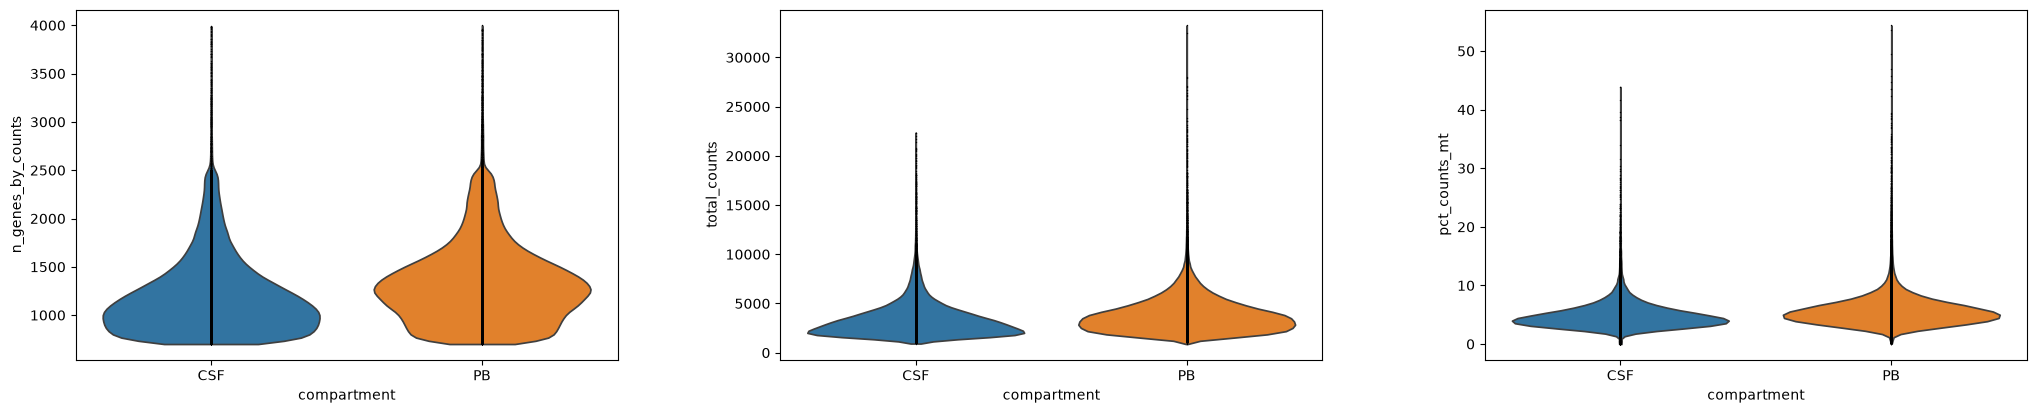

In [ ]:
# Compare QC metric distributions between PB and CSF

sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    groupby="compartment",
    jitter=0,
    multi_panel=True
)

In [ ]:
### QC distributions by compartment

PB and CSF cells show somewhat different QC distributions. PB cells generally
have higher numbers of detected genes and total UMI counts, and a slightly
higher mitochondrial percentage.

Most cells in both compartments have relatively low mitochondrial percentages,
while a small number of cells form high-value tails.

These differences suggest that QC thresholds should be selected carefully
rather than applying arbitrary cutoffs without considering compartment and
sample-level variation.

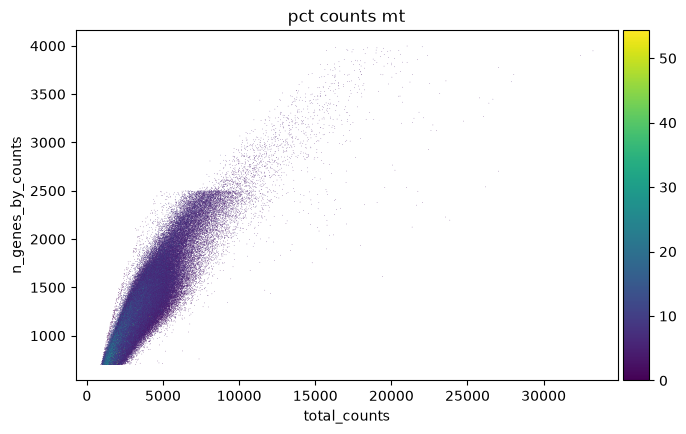

In [ ]:
# Examine the relationship between total counts and detected genes

sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt"
)

### Relationship between counts and detected genes

The number of detected genes increases with total UMI counts, as expected.

Most cells form a continuous main population with relatively low mitochondrial
percentages. A small number of cells show unusually high counts, gene numbers,
or mitochondrial percentages and may represent QC outliers.

These cells will be evaluated before filtering.

In [ ]:
# Summarize QC metrics for each sample

sample_qc = (
    adata.obs
    .groupby("GSM", observed=True)
    .agg(
        n_cells=("GSM", "size"),
        median_counts=("total_counts", "median"),
        median_genes=("n_genes_by_counts", "median"),
        median_mt=("pct_counts_mt", "median")
    )
    .sort_values("median_mt", ascending=False)
)

display(sample_qc)

,n_cells,median_counts,median_genes,median_mt
GSM,,,,
GSM5264639,3239,3038.0,1234.0,7.184400
GSM5264642,5166,3906.5,1368.5,7.025389
GSM5264638,13317,2737.0,1193.0,6.837080
GSM5264645,2724,3021.5,1202.5,6.487262
GSM5264646,5173,2169.0,872.0,6.192171
GSM5264635,4527,4231.0,1332.0,5.725389
GSM5264658,7779,3586.0,1366.0,5.610561
GSM5264641,2354,2882.0,1215.0,5.609398
GSM5264656,4046,3675.0,1286.0,5.545121


In [ ]:
### Sample-level QC

QC metrics vary across the 38 samples, but no sample shows an obviously
extreme median mitochondrial percentage or gene count that would justify
removing the entire sample.

Cell-level outliers will therefore be evaluated before applying QC filters.

In [ ]:
# Evaluate potential QC thresholds before filtering

print("Total cells:", adata.n_obs)

print("\nHigh mitochondrial percentage:")
for threshold in [10, 12.5, 15, 20]:
    n = (adata.obs["pct_counts_mt"] > threshold).sum()
    pct = n / adata.n_obs * 100
    print(f"> {threshold}% MT: {n:,} cells ({pct:.2f}%)")

print("\nLow number of detected genes:")
for threshold in [700, 750, 800, 900]:
    n = (adata.obs["n_genes_by_counts"] < threshold).sum()
    pct = n / adata.n_obs * 100
    print(f"< {threshold} genes: {n:,} cells ({pct:.2f}%)")

print("\nHigh number of detected genes:")
for threshold in [2500, 3000, 3500]:
    n = (adata.obs["n_genes_by_counts"] > threshold).sum()
    pct = n / adata.n_obs * 100
    print(f"> {threshold} genes: {n:,} cells ({pct:.2f}%)")

Total cells: 175895

High mitochondrial percentage:
> 10% MT: 6,301 cells (3.58%)
> 12.5% MT: 2,536 cells (1.44%)
> 15% MT: 1,327 cells (0.75%)
> 20% MT: 454 cells (0.26%)

Low number of detected genes:
< 700 genes: 0 cells (0.00%)
< 750 genes: 6,683 cells (3.80%)
< 800 genes: 14,162 cells (8.05%)
< 900 genes: 30,218 cells (17.18%)

High number of detected genes:
> 2500 genes: 1,374 cells (0.78%)
> 3000 genes: 486 cells (0.28%)
> 3500 genes: 147 cells (0.08%)


In [ ]:
# Evaluate the combined effect of conservative QC thresholds

qc_pass = (
    (adata.obs["n_genes_by_counts"] >= 750) &
    (adata.obs["pct_counts_mt"] < 15)
)

n_pass = qc_pass.sum()
n_remove = (~qc_pass).sum()

print("Cells before QC:", adata.n_obs)
print("Cells passing QC:", n_pass)
print("Cells removed:", n_remove)
print(f"Percentage removed: {n_remove / adata.n_obs * 100:.2f}%")

Cells before QC: 175895
Cells passing QC: 168077
Cells removed: 7818
Percentage removed: 4.44%


In [ ]:
# Check whether the candidate QC thresholds affect PB and CSF differently

qc_check = pd.crosstab(
    adata.obs["compartment"],
    qc_pass,
    normalize="index"
) * 100

qc_check.columns = ["Fail QC", "Pass QC"]

display(qc_check)

,Fail QC,Pass QC
compartment,,
CSF,5.743445,94.256555
PB,3.874009,96.125991


In [ ]:
# Apply QC filtering

adata = adata[qc_pass].copy()

print("Cells after QC:", adata.n_obs)
print("Genes:", adata.n_vars)

print("\nCells by compartment:")
print(adata.obs["compartment"].value_counts())

print("\nCells by disease status:")
print(adata.obs["disease_status"].value_counts())

NameError: name 'adata' is not defined

### Cell filtering

Cells with fewer than 750 detected genes or ≥15% mitochondrial counts were
excluded. These conservative thresholds removed 7,818 cells (4.44% of the
dataset).

The filtering retained 94.3% of CSF cells and 96.1% of PB cells, avoiding
strong depletion of either compartment.

In [ ]:
print("Scanpy version:", sc.__version__)
print("Scrublet available:", hasattr(sc.pp, "scrublet"))

Scanpy version: 1.11.5
Scrublet available: True


/tmp/ipykernel_252176/2442336873.py:1: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy version:", sc.__version__)


In [ ]:
# Save a checkpoint after QC

adata.write("../data/adata_after_qc.h5ad")

print("Saved:", adata.shape)

Saved: (168077, 33538)


In [24]:
import scanpy as sc
import pandas as pd
import numpy as np
import skimage

# Reload our saved QC checkpoint
adata = sc.read_h5ad("../data/adata_after_qc.h5ad")

print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Columns:", adata.obs.columns.tolist())

Cells: 168077
Genes: 33538
Columns: ['GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt']


In [23]:
# Doublet detection per sample/library
import skimage

print("scikit-image installed successfully")
sc.pp.scrublet(
    adata,
    batch_key="GSM"
)

print("Doublet detection finished!")

print("\nPredicted doublets:")
print(adata.obs["predicted_doublet"].value_counts())

print("\nPredicted doublet percentage:")
print(
    adata.obs["predicted_doublet"]
    .value_counts(normalize=True)
    .mul(100)
)

scikit-image installed successfully


KeyboardInterrupt: 

In [ ]:
# Check doublet rate for each GSM sample

doublet_by_sample = (
    adata.obs
    .groupby("GSM", observed=True)["predicted_doublet"]
    .agg(["sum", "count"])
)

doublet_by_sample["doublet_percent"] = (
    doublet_by_sample["sum"] /
    doublet_by_sample["count"] * 100
)

doublet_by_sample = doublet_by_sample.sort_values(
    "doublet_percent",
    ascending=False
)

display(doublet_by_sample)

,sum,count,doublet_percent
GSM,,,
GSM5264664,164,4208,3.897338
GSM5264650,236,8989,2.625431
GSM5264640,235,8960,2.622768
GSM5264655,23,887,2.593010
GSM5264671,86,3705,2.321188
GSM5264668,121,6245,1.937550
GSM5264637,105,6085,1.725555
GSM5264666,91,5323,1.709562
GSM5264634,8,468,1.709402


In [ ]:
doublet_qc = (
    adata.obs
    .groupby("predicted_doublet", observed=True)[
        ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
    ]
    .median()
)

display(doublet_qc)

KeyError: 'predicted_doublet'

In [ ]:
# Keep only predicted singlets

adata = adata[~adata.obs["predicted_doublet"]].copy()

print("Cells after doublet removal:", adata.n_obs)
print("Genes:", adata.n_vars)

NameError: name 'adata' is not defined

In [ ]:
# Preserve the original raw counts for later pseudobulk analysis
adata.layers["counts"] = adata.X.copy()

print("Raw counts stored:", "counts" in adata.layers)
print("Current shape:", adata.shape)

NameError: name 'adata' is not defined

In [ ]:
adata.write("../data/adata_after_qc_doublets.h5ad")

print("QC + doublet checkpoint saved!")

NameError: name 'adata' is not defined

In [ ]:
# Normalize each cell to a total of 10,000 counts
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

# Log-transform normalized expression
sc.pp.log1p(adata)

print("Normalization and log transformation complete!")
print(adata)

Normalization and log transformation complete!
AnnData object with n_obs × n_vars = 168077 × 33538
    obs: 'GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'compartment_colors', 'pca', 'log1p', 'hvg'
    obsm: 'X_pca'
    varm: 'PCs'


In [ ]:
# ============================================================
# STEP: Select Highly Variable Genes (HVGs)
# ============================================================
# Our dataset contains 33,538 genes, but not all genes are useful
# for distinguishing different cell types or cell states.
#
# Highly Variable Genes (HVGs) are genes whose expression varies
# strongly across cells and therefore contains useful biological
# information for dimensionality reduction and clustering.
#
# We select the top 3,000 HVGs instead of using all 33,538 genes
# for PCA and downstream construction of the neighbor graph/UMAP.
#
# batch_key="GSM" accounts for the fact that the dataset contains
# multiple samples/libraries, helping avoid selecting genes that
# appear variable mainly because of one particular sample.
#
# flavor="seurat" is appropriate here because adata.X has already
# been normalized and log-transformed.
#
# IMPORTANT:
# This does NOT delete the other genes.
# It adds a True/False flag in:
#     adata.var["highly_variable"]
#
# Raw UMI counts remain preserved in:
#     adata.layers["counts"]
# ============================================================

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=3000,
    flavor="seurat",
    batch_key="GSM"
)

print("Number of highly variable genes:")
print(adata.var["highly_variable"].sum())

Number of highly variable genes:
3000


In [ ]:
# ============================================================
# STEP: Principal Component Analysis (PCA)
# ============================================================
# We selected 3,000 highly variable genes (HVGs), but this is
# still too many dimensions to directly compare and cluster cells.
#
# PCA compresses the expression patterns of these HVGs into a
# smaller number of "principal components" (PCs).
#
# Each PC captures a major axis of variation between cells.
# For example, some PCs may later reflect differences between
# immune cell types, cell states, or technical/sample effects.
#
# We use only the genes marked as highly variable for PCA.
#
# IMPORTANT:
# PCA does NOT remove the original genes or raw counts.
# The PCA coordinates will be stored in:
#     adata.obsm["X_pca"]
# ============================================================

sc.tl.pca(
    adata,
    n_comps=50,
    use_highly_variable=True
)

print("PCA complete!")
print("PCA shape:", adata.obsm["X_pca"].shape)

/home/operation/miniconda3/envs/scrna_pipeline/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


PCA complete!
PCA shape: (168077, 50)


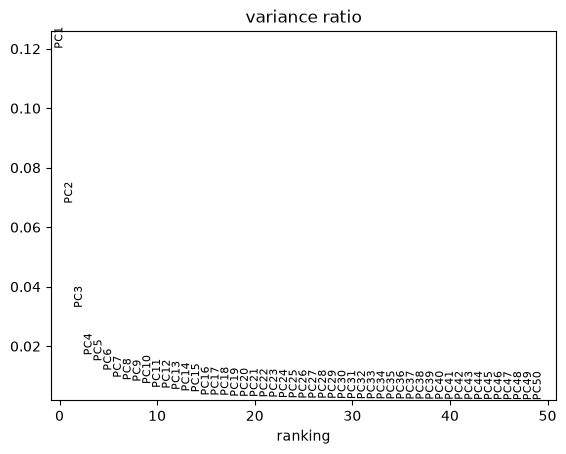

In [ ]:
# ============================================================
# STEP: Inspect PCA variance
# ============================================================
# PCA created 50 principal components (PCs).
#
# The first PCs usually capture more variation in gene expression,
# while later PCs progressively capture less.
#
# This plot helps us decide how many PCs should be used to build
# the cell-cell neighbor graph.
#
# We look for where the explained variance begins to level off
# ("elbow") rather than automatically using all 50 PCs.
# ============================================================

sc.pl.pca_variance_ratio(
    adata,
    n_pcs=50,
    log=False
)

### PCA variance

The first principal components explain the largest fraction of expression
variation, with a particularly strong contribution from PC1. The explained
variance decreases rapidly across the early PCs and becomes progressively
flatter in later components.

Thirty PCs will initially be used to construct the neighborhood graph.
The relationship between the PCA structure and biological/technical metadata
will also be examined before interpreting the resulting clusters.

In [ ]:
# ============================================================
# STEP: Build the cell-cell neighborhood graph
# ============================================================
# PCA represents every cell using a smaller number of dimensions.
#
# We now identify cells with similar PCA expression profiles and
# connect them in a nearest-neighbor graph.
#
# This graph is the basis for:
#     - UMAP visualization
#     - clustering
#
# We use the first 30 PCs as a starting point.
#
# n_neighbors=15 means that the local neighborhood of each cell
# is constructed using approximately its 15 nearest neighbors.
# ============================================================

sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30
)

print("Neighbor graph constructed!")

Neighbor graph constructed!


In [ ]:
# ============================================================
# STEP: UMAP dimensionality reduction
# ============================================================
# The neighbor graph describes which cells have similar
# gene-expression profiles in PCA space.
#
# UMAP converts this high-dimensional neighborhood structure
# into two dimensions so that we can visualize the relationships
# among the 166,599 cells.
#
# Cells positioned close together on the UMAP generally have
# similar transcriptomic profiles.
#
# IMPORTANT:
# UMAP coordinates themselves are mainly for visualization.
# Distances and cluster shapes should not be interpreted as exact
# quantitative biological distances.
#
# The UMAP coordinates will be stored in:
#     adata.obsm["X_umap"]
# ============================================================

sc.tl.umap(adata)

print("UMAP calculated!")
print("UMAP shape:", adata.obsm["X_umap"].shape)

UMAP calculated!
UMAP shape: (168077, 2)


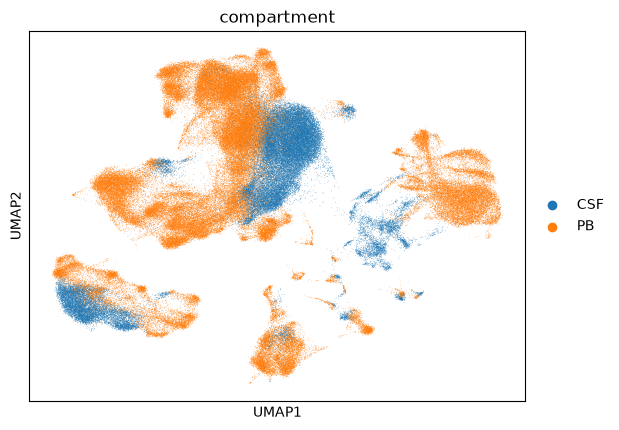

In [ ]:
# ============================================================
# STEP: Visualize UMAP by biological compartment
# ============================================================
# UMAP has reduced the neighborhood structure of our cells
# to two dimensions: UMAP1 and UMAP2.
#
# We first color the cells by their tissue compartment:
#     PB  = peripheral blood
#     CSF = cerebrospinal fluid
#
# This allows us to examine whether PB and CSF cells occupy
# similar or different regions of the transcriptomic landscape.
#
# IMPORTANT:
# We have NOT yet assigned cell types.
# Therefore, we should not yet call individual UMAP regions
# "T cells", "B cells", etc.
# ============================================================

sc.pl.umap(
    adata,
    color="compartment"
)

In [ ]:
# ============================================================
# STEP: Leiden clustering
# ============================================================
# Leiden identifies communities of cells in the neighbor graph.
#
# resolution=0.5:
#     starting clustering granularity
#
# flavor="igraph":
#     use igraph's Leiden implementation
#
# n_iterations=2 and directed=False:
#     settings recommended by current Scanpy for this backend
# ============================================================

sc.tl.leiden(
    adata,
    resolution=0.5,
    key_added="leiden_0_5",
    flavor="igraph",
    n_iterations=2,
    directed=False
)

print(
    adata.obs["leiden_0_5"]
    .value_counts()
    .sort_index()
)

leiden_0_5
0     19126
1      3678
2     18194
3     13726
4     22602
5      4030
6     13785
7      4583
8      5001
9     13863
10    11427
11      696
12     8556
13      889
14     1881
15     1962
16      826
17     1091
18      228
19     3641
20    16390
21      225
22     1677
Name: count, dtype: int64


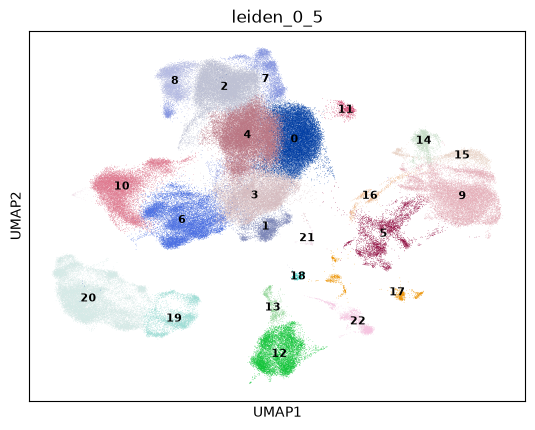

In [ ]:
# ============================================================
# STEP: Visualize Leiden clusters on the UMAP
# ============================================================
# Leiden clustering identified 23 communities of cells.
#
# Each number (0–22) is currently only a cluster ID.
# It does NOT yet represent a biological cell type.
#
# By displaying the cluster labels on the UMAP, we can examine
# how the graph-based clusters correspond to the transcriptomic
# structure that we saw previously.
#
# NEXT:
# After inspecting the clustering, we will identify marker genes
# for each cluster and use them to assign biological cell types.
# ============================================================

sc.pl.umap(
    adata,
    color="leiden_0_5",
    legend_loc="on data",
    legend_fontsize=8
)

In [ ]:
# ============================================================
# STEP: Identify marker genes for each Leiden cluster
# ============================================================
# We currently have 23 anonymous clusters (0–22).
#
# To determine their biological identities, we compare the
# expression profile of each cluster with the other cells.
#
# This identifies genes that are enriched in each cluster.
#
# For example, later we may see patterns such as:
#
#     CD3D / CD3E / TRAC  -> T-cell-associated
#     MS4A1 / CD79A       -> B-cell-associated
#     NKG7 / GNLY         -> NK/cytotoxic-associated
#     LST1 / CTSS         -> myeloid-associated
#
# IMPORTANT:
# Cell-type annotation should be based on combinations of
# markers, not on a single gene.
#
# method="wilcoxon" performs a non-parametric comparison between
# cells in each cluster and the remaining cells.
# ============================================================

sc.tl.rank_genes_groups(
    adata,
    groupby="leiden_0_5",
    method="wilcoxon",
    use_raw=False
)

print("Marker-gene analysis complete!")

Marker-gene analysis complete!


/home/operation/miniconda3/envs/scrna_pipeline/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/home/operation/miniconda3/envs/scrna_pipeline/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/home/operation/miniconda3/envs/scrna_pipeline/lib/python3.11/site-packages/scanpy/tool

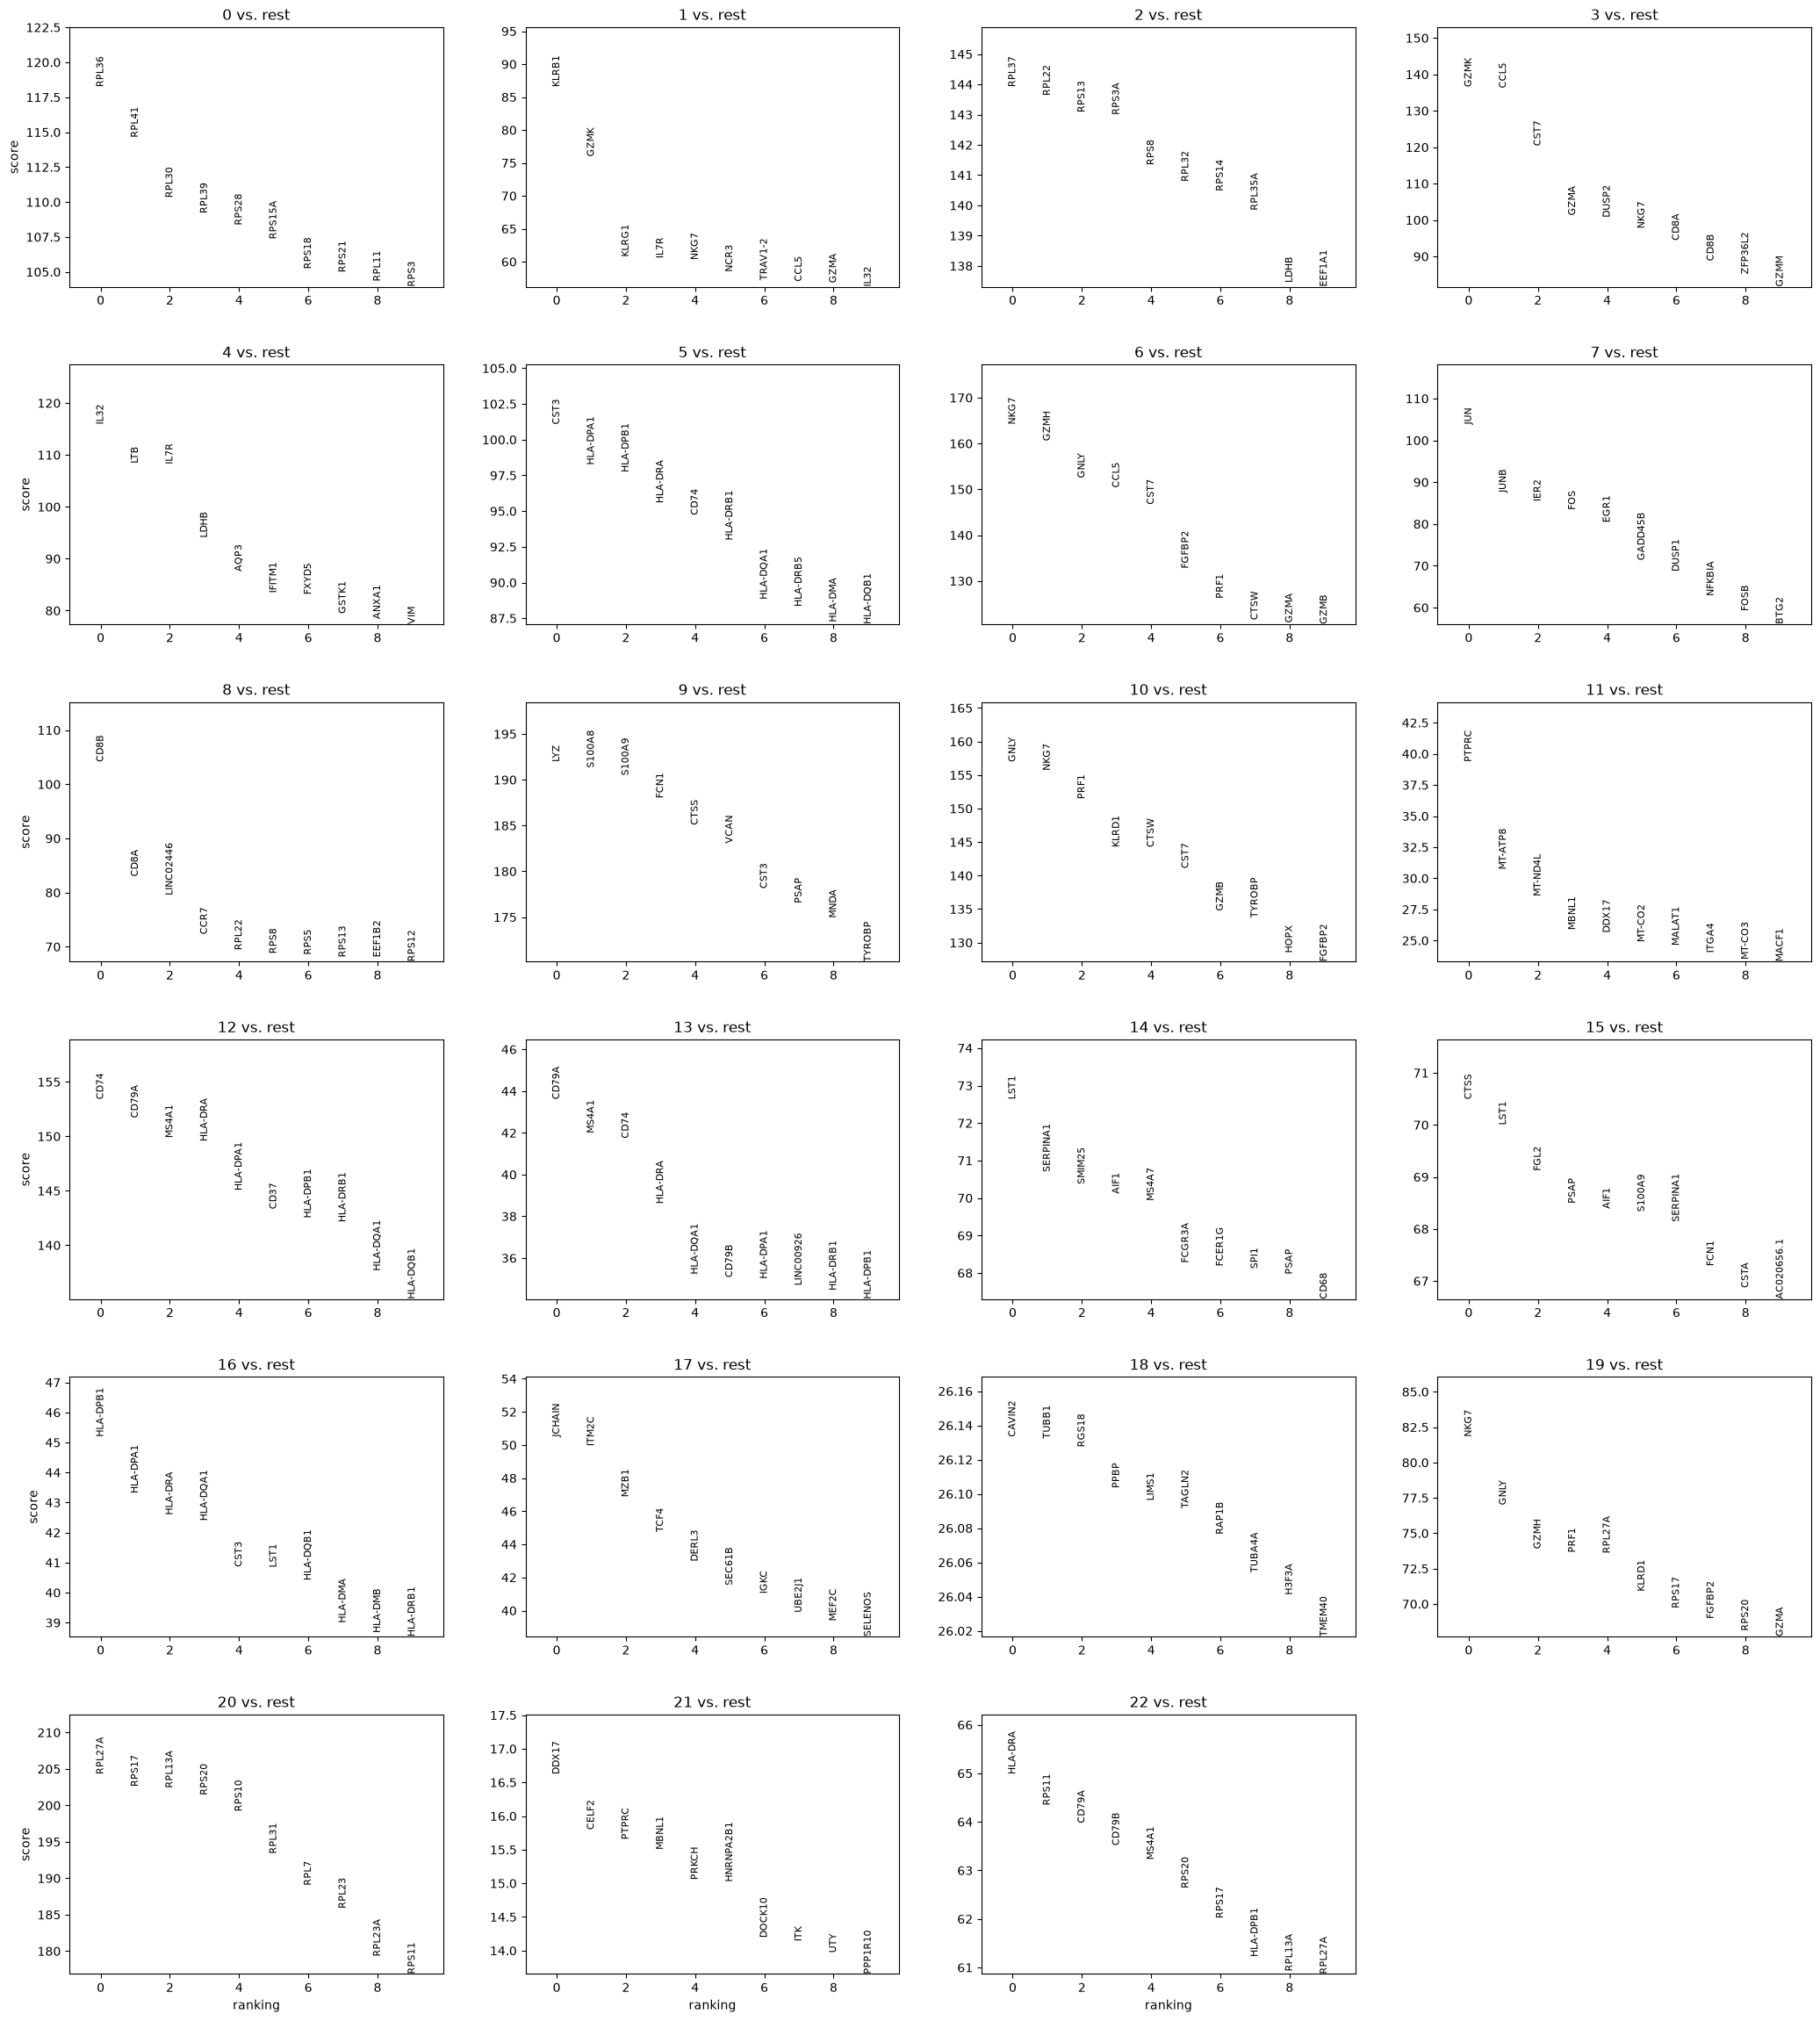

In [ ]:
sc.pl.rank_genes_groups(
    adata,
    n_genes=10,
    sharey=False
)

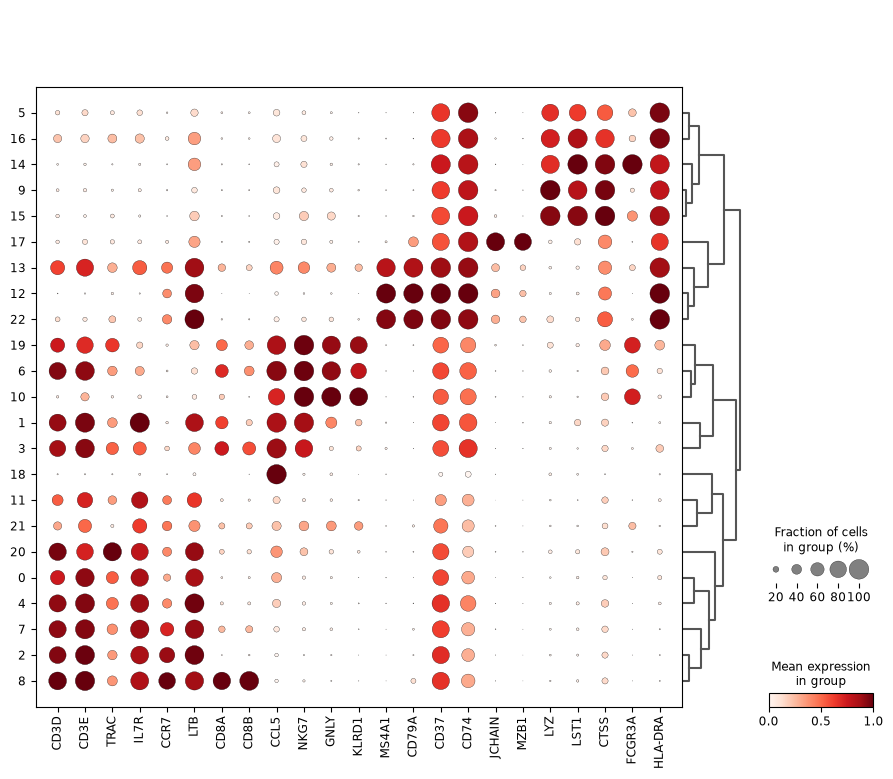

In [ ]:
# ============================================================
# STEP: Examine canonical immune-cell markers
# ============================================================
# The top-ranked genes give us clues about cluster identity,
# but cell types should not be assigned from one marker alone.
#
# Here we examine combinations of established lineage markers
# across all 23 Leiden clusters.
#
# The dot plot shows:
#   - dot size  -> fraction of cells expressing the gene
#   - dot color -> average expression of the gene
#
# We will use marker combinations to distinguish major immune
# populations before attempting finer subtyping.
# ============================================================

marker_genes = [
    # T cells
    "CD3D", "CD3E", "TRAC",

    # CD4 / naive-memory-associated T cells
    "IL7R", "CCR7", "LTB",

    # CD8 / cytotoxic lymphocytes
    "CD8A", "CD8B", "CCL5",

    # NK / cytotoxic program
    "NKG7", "GNLY", "KLRD1",

    # B cells
    "MS4A1", "CD79A", "CD37", "CD74",

    # Plasma cells
    "JCHAIN", "MZB1",

    # Myeloid / monocytes
    "LYZ", "LST1", "CTSS", "FCGR3A",

    # HLA / antigen presentation
    "HLA-DRA"
]

# Keep only genes that actually exist in this dataset
marker_genes = [g for g in marker_genes if g in adata.var_names]

sc.pl.dotplot(
    adata,
    marker_genes,
    groupby="leiden_0_5",
    standard_scale="var",
    dendrogram=True
)

Markers available: ['CD3D', 'CD3E', 'TRAC', 'CCR7', 'SELL', 'TCF7', 'LEF1', 'MAL', 'CD4', 'IL7R', 'LTB', 'CD8A', 'CD8B', 'CCL5', 'NKG7', 'GNLY', 'GZMK', 'GZMB', 'PRF1', 'KLRD1', 'FCGR3A', 'TRDC', 'FOXP3', 'IL2RA', 'CTLA4']


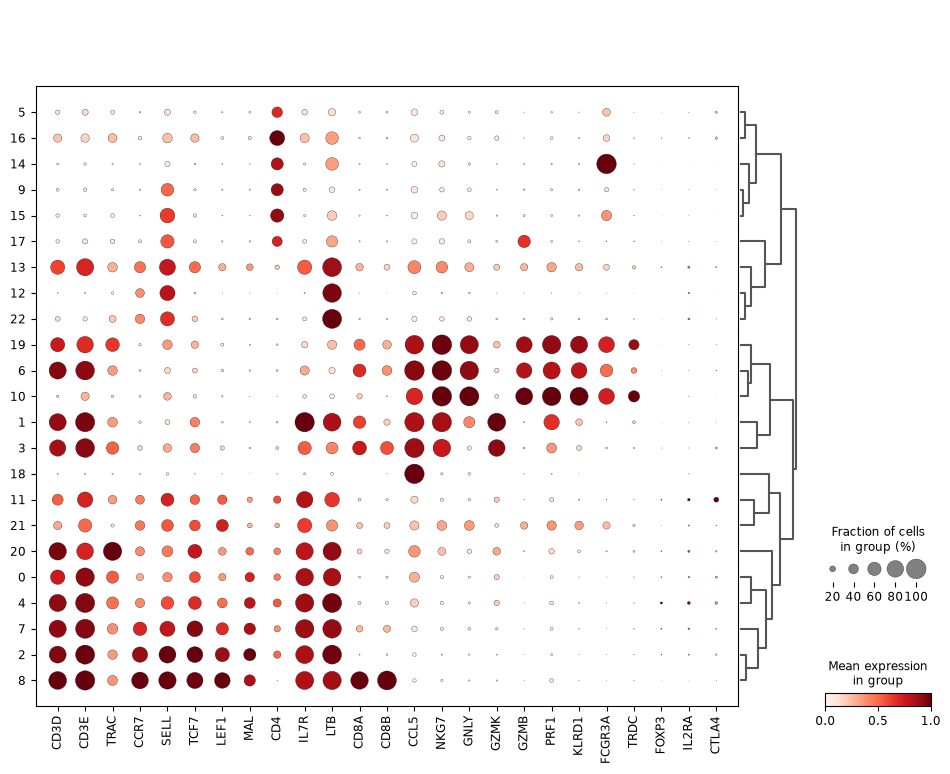

In [ ]:
# ============================================================
# STEP: Refine T-cell and NK-cell annotation
# ============================================================
# The first marker analysis showed that many Leiden clusters
# belong to the T-cell / cytotoxic lymphocyte compartment.
#
# We now use a more detailed marker panel to distinguish:
#
#   - General T cells
#   - Naive / central-memory-like T cells
#   - CD4-associated populations
#   - CD8-associated populations
#   - Cytotoxic T cells
#   - Regulatory T-cell-associated populations
#   - NK cells
#
# IMPORTANT:
# No subtype will be assigned from one gene alone.
# We will interpret combinations of markers.
# ============================================================

t_nk_markers = [
    # General T-cell markers
    "CD3D", "CD3E", "TRAC",

    # Naive / central-memory-associated
    "CCR7", "SELL", "TCF7", "LEF1", "MAL",

    # CD4-associated
    "CD4", "IL7R", "LTB",

    # CD8-associated
    "CD8A", "CD8B",

    # Cytotoxic program
    "CCL5", "NKG7", "GNLY",
    "GZMK", "GZMB", "PRF1",

    # NK-associated
    "KLRD1", "FCGR3A", "TRDC",

    # Regulatory T-cell-associated
    "FOXP3", "IL2RA", "CTLA4"
]

# Keep only genes present in our dataset
t_nk_markers = [
    gene for gene in t_nk_markers
    if gene in adata.var_names
]

print("Markers available:", t_nk_markers)

sc.pl.dotplot(
    adata,
    t_nk_markers,
    groupby="leiden_0_5",
    standard_scale="var",
    dendrogram=True
)

Markers available: ['CD79A', 'MS4A1', 'CD37', 'CD74', 'CD19', 'CD22', 'TCL1A', 'IGHD', 'IGHM', 'FCER2', 'CD27', 'AIM2', 'TNFRSF13B', 'JCHAIN', 'MZB1', 'SDC1', 'XBP1', 'PRDM1']


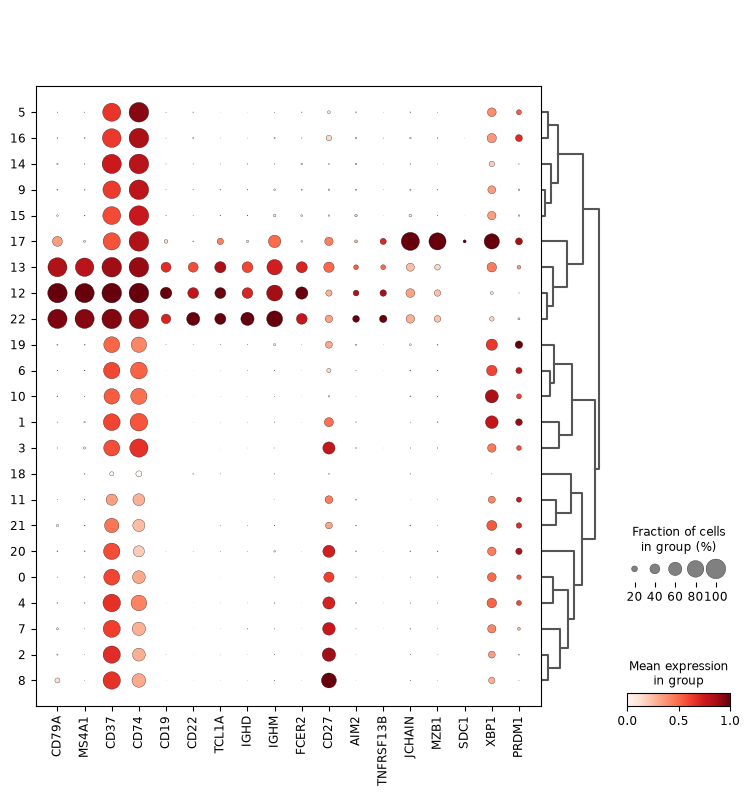

In [ ]:
# ============================================================
# STEP: Refine B-cell and plasma-cell annotation
# ============================================================
# Our first marker analysis suggested that clusters 12, 13 and 22
# contain B-cell-like populations, while cluster 17 appears
# plasma-cell / antibody-secreting-cell-like.
#
# We now examine a more detailed B-lineage marker panel.
#
# We are looking for combinations of:
#
# General B-cell identity:
#     CD79A, MS4A1, CD37, CD74, CD19, CD22
#
# Naive B-cell-associated:
#     TCL1A, IGHD, IGHM, FCER2
#
# Memory B-cell-associated:
#     CD27, AIM2, TNFRSF13B
#
# Plasma / antibody-secreting-cell-associated:
#     JCHAIN, MZB1, SDC1, XBP1, PRDM1
#
# Again, annotation will be based on combinations of genes,
# not a single marker.
# ============================================================

b_cell_markers = [
    # General B cells
    "CD79A", "MS4A1", "CD37", "CD74", "CD19", "CD22",

    # Naive B-associated
    "TCL1A", "IGHD", "IGHM", "FCER2",

    # Memory B-associated
    "CD27", "AIM2", "TNFRSF13B",

    # Plasma / antibody-secreting cells
    "JCHAIN", "MZB1", "SDC1", "XBP1", "PRDM1"
]

b_cell_markers = [
    gene for gene in b_cell_markers
    if gene in adata.var_names
]

print("Markers available:", b_cell_markers)

sc.pl.dotplot(
    adata,
    b_cell_markers,
    groupby="leiden_0_5",
    standard_scale="var",
    dendrogram=True
)

Markers available: ['LYZ', 'LST1', 'CTSS', 'TYROBP', 'FCER1G', 'S100A8', 'S100A9', 'CTSD', 'FCN1', 'VCAN', 'CCR2', 'FCGR3A', 'MS4A7', 'LILRB1', 'IFITM3', 'FCER1A', 'CD1C', 'CLEC10A', 'HLA-DRA', 'HLA-DPA1', 'HLA-DPB1', 'GZMB', 'TCF4', 'IL3RA']


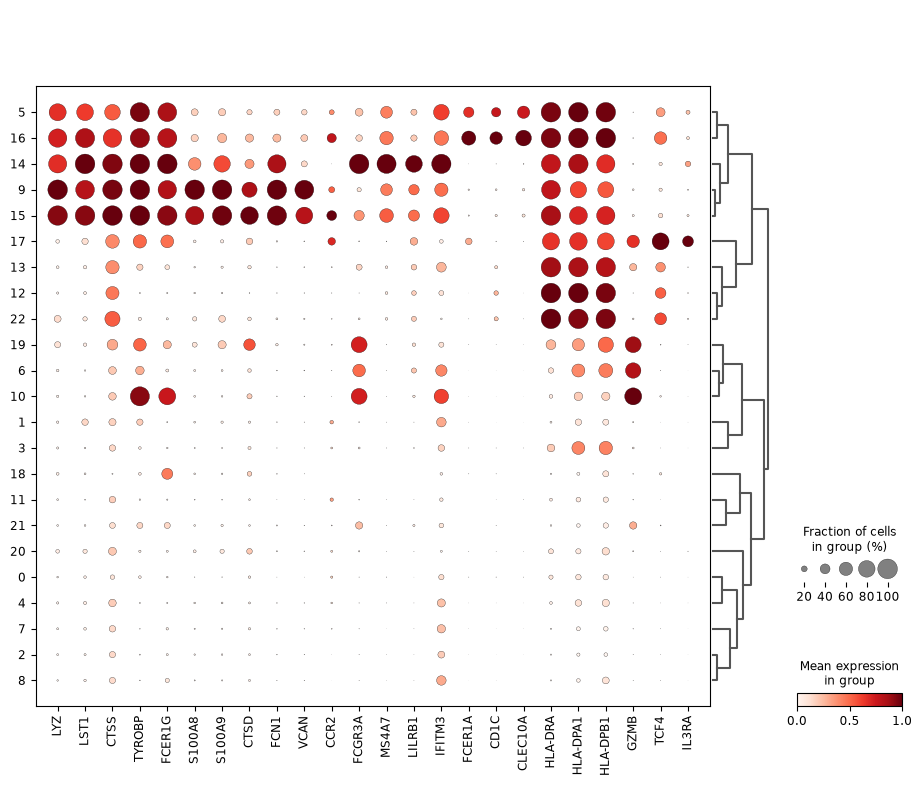

In [ ]:
# ============================================================
# STEP: Refine myeloid / antigen-presenting cell annotation
# ============================================================
# Our previous marker analysis suggested that clusters
# 5, 9, 14, 15 and 16 belong mainly to the myeloid/APC
# compartment.
#
# We now examine markers that can help distinguish:
#
#   - General myeloid cells
#   - Classical monocytes
#   - Non-classical monocytes
#   - Dendritic-cell-associated populations
#
# As before, identities will be assigned from marker
# combinations rather than individual genes.
# ============================================================

myeloid_markers = [
    # General myeloid
    "LYZ", "LST1", "CTSS", "TYROBP", "FCER1G",

    # Classical monocyte-associated
    "S100A8", "S100A9", "CTSD", "FCN1", "VCAN", "CCR2",

    # Non-classical monocyte-associated
    "FCGR3A", "MS4A7", "LILRB1", "IFITM3",

    # Conventional dendritic-cell-associated
    "FCER1A", "CD1C", "CLEC10A",

    # DC-associated / antigen presentation
    "HLA-DRA", "HLA-DPA1", "HLA-DPB1",

    # pDC-associated
    "GZMB", "GZMB", "TCF4", "IL3RA", "GZMB"
]

# Remove duplicates and genes absent from the dataset
myeloid_markers = list(dict.fromkeys(
    gene for gene in myeloid_markers
    if gene in adata.var_names
))

print("Markers available:", myeloid_markers)

sc.pl.dotplot(
    adata,
    myeloid_markers,
    groupby="leiden_0_5",
    standard_scale="var",
    dendrogram=True
)

In [ ]:
# ============================================================
# STEP: Investigate unresolved clusters
# ============================================================
# Most major populations can now be assigned to broad immune
# lineages.
#
# Clusters 11, 18 and 21 remain unclear from our canonical
# marker panels.
#
# We therefore inspect a larger set of their cluster-enriched
# genes before assigning an identity.
#
# Small clusters are NOT automatically artifacts or rare cell
# types. Their marker patterns must be examined first.
# ============================================================

for cluster in ["11", "18", "21"]:

    print("\n" + "=" * 50)
    print(f"CLUSTER {cluster}")
    print("=" * 50)

    markers = sc.get.rank_genes_groups_df(
        adata,
        group=cluster
    )

    print(
        markers[
            ["names", "scores", "logfoldchanges", "pvals_adj"]
        ].head(20).to_string(index=False)
    )


CLUSTER 11
   names    scores  logfoldchanges     pvals_adj
   PTPRC 39.348267        1.193076  0.000000e+00
 MT-ATP8 30.699732        1.218803 2.047523e-204
 MT-ND4L 28.553211        0.823200 8.185103e-177
   MBNL1 25.852093        1.472792 6.780529e-145
   DDX17 25.621223        1.644070 2.537256e-142
  MT-CO2 24.870127        0.256087 4.237166e-134
  MALAT1 24.588961        0.281791 4.378288e-131
   ITGA4 24.007309        2.105146 5.926514e-125
  MT-CO3 23.469751        0.255206 2.049249e-119
   MACF1 23.302523        2.246148 1.023214e-117
   ITGB1 23.105980        1.731006 9.657795e-116
  MT-CO1 23.094952        0.222390 1.237743e-115
  SPOCK2 22.862764        1.819445 2.540955e-113
  MT-ND3 22.399540        0.279480 8.951039e-109
KIAA1551 22.280325        1.798486 1.273559e-107
   AHNAK 22.207045        1.316372 6.436264e-107
    TC2N 21.458399        1.971090 7.940799e-100
  RIPOR2 21.216394        1.117656  1.386783e-97
  MT-CYB 21.166328        0.243235  3.991477e-97
   SYNE2

In [ ]:
# ============================================================
# STEP: Create first biological cell-type annotation
# ============================================================
# Leiden gave us 23 computational clusters.
#
# We now translate those numerical clusters into biological
# identities using:
#
#   1. Cluster-enriched genes
#   2. Canonical immune-cell marker combinations
#   3. T/NK-specific marker analysis
#   4. B/plasma-specific marker analysis
#   5. Myeloid/APC-specific marker analysis
#
# IMPORTANT:
# These are first-pass biological annotations.
# We deliberately keep uncertain populations broad rather than
# assigning overly specific identities without enough evidence.
# ============================================================

cell_type_map = {

    # T-cell populations
    "0":  "Naive/memory-like T",
    "2":  "Naive/memory-like T",
    "4":  "Naive/memory-like T",
    "7":  "Naive/memory-like T",
    "8":  "CD8 naive-like T",
    "20": "Naive/memory-like T",

    # Cytotoxic T
    "1":  "Cytotoxic T",
    "3":  "Cytotoxic T",

    # NK / strongly cytotoxic lymphocytes
    "6":  "NK",
    "10": "NK",
    "19": "NK",

    # B lineage
    "12": "Naive B",
    "13": "Memory-like B",
    "22": "B cell - unresolved",

    # Antibody-secreting cells
    "17": "Plasma/antibody-secreting",

    # Myeloid / APC
    "15": "Classical monocyte",
    "9":  "FCGR3A+ monocyte",
    "14": "FCGR3A+ monocyte",
    "5":  "Dendritic/APC-like",
    "16": "Dendritic/APC-like",

    # Platelet lineage
    "18": "Platelet",

    # Still unresolved
    "11": "Unresolved leukocyte",
    "21": "T cell - unresolved"
}

adata.obs["cell_type"] = (
    adata.obs["leiden_0_5"]
    .astype(str)
    .map(cell_type_map)
)

print(adata.obs["cell_type"].value_counts())
print("\nMissing annotations:",
      adata.obs["cell_type"].isna().sum())

cell_type
Naive/memory-like T          80895
NK                           28853
Cytotoxic T                  17404
FCGR3A+ monocyte             15744
Naive B                       8556
CD8 naive-like T              5001
Dendritic/APC-like            4856
Classical monocyte            1962
B cell - unresolved           1677
Plasma/antibody-secreting     1091
Memory-like B                  889
Unresolved leukocyte           696
Platelet                       228
T cell - unresolved            225
Name: count, dtype: int64

Missing annotations: 0


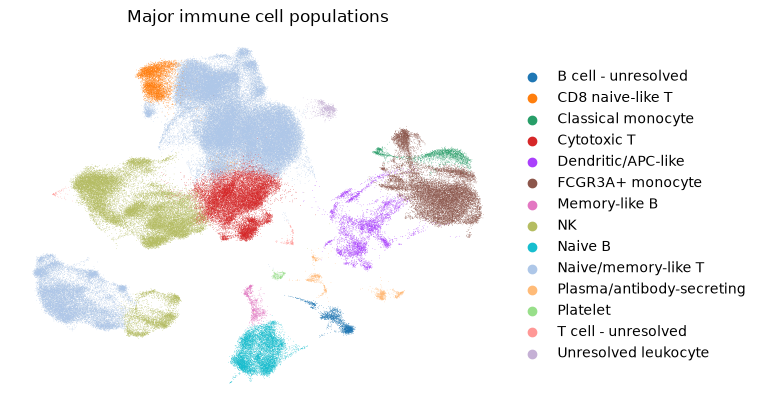

In [ ]:
# ============================================================
# STEP: Visualize biologically annotated cell populations
# ============================================================
# Each cell now has a first-pass biological identity based on
# its Leiden cluster and the marker-gene patterns we examined.
#
# This replaces anonymous cluster numbers with interpretable
# biological labels.
#
# Some labels remain intentionally broad or unresolved because
# the available marker evidence does not yet justify a more
# specific annotation.
# ============================================================

sc.pl.umap(
    adata,
    color="cell_type",
    legend_loc="right margin",
    title="Major immune cell populations",
    frameon=False
)

In [ ]:
adata.write("../data/adata_annotated.h5ad")

print("Annotated dataset saved!")

Annotated dataset saved!


In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 1
# Examine disease and compartment structure
# ============================================================
# Before testing disease-associated differences, we need to
# understand how the biological samples are distributed.
#
# IMPORTANT:
# Cells are NOT independent biological replicates.
# The donor is the biological replicate.
#
# Therefore, we inspect:
#   - disease status
#   - compartment (PB / CSF)
#   - donor
#   - number of cells contributed by each donor
#
# We keep CIS, NMO and Uveitis separate from Healthy.
# ============================================================

sample_overview = (
    adata.obs
    .groupby(
        ["disease_status", "donor", "compartment"],
        observed=True
    )
    .size()
    .reset_index(name="n_cells")
)

print(sample_overview.to_string(index=False))

              disease_status donor compartment  n_cells
Clinically isolated syndrome    22         CSF      887
Clinically isolated syndrome    22          PB     3977
Clinically isolated syndrome    31         CSF     4828
Clinically isolated syndrome    31          PB    13383
                     Healthy     2         CSF      468
                     Healthy     2          PB     4438
                     Healthy     3         CSF     1417
                     Healthy     3          PB     6085
                     Healthy    32         CSF     3495
                     Healthy    32          PB     3705
        Neuromyelitis optica     5          PB    12966
                Relapsing MS     6         CSF     3031
                Relapsing MS     6          PB     8960
                Relapsing MS     7         CSF     2331
                Relapsing MS     7          PB     4914
                Relapsing MS     8         CSF     3917
                Relapsing MS     8          PB  

In [ ]:
# Number of cells by disease and compartment

disease_compartment = pd.crosstab(
    adata.obs["disease_status"],
    adata.obs["compartment"]
)

print(disease_compartment)

compartment                     CSF     PB
disease_status                            
Clinically isolated syndrome   5715  17360
Healthy                        5380  14228
Neuromyelitis optica              0  12966
Relapsing MS                  36033  68507
Uveitis                        3484   4404


In [ ]:
# Number of unique donors by disease and compartment

donor_overview = (
    adata.obs
    .groupby(
        ["disease_status", "compartment"],
        observed=True
    )["donor"]
    .nunique()
    .unstack(fill_value=0)
)

print(donor_overview)

compartment                   CSF  PB
disease_status                       
Clinically isolated syndrome    2   2
Healthy                         3   3
Neuromyelitis optica            0   1
Relapsing MS                   12  12
Uveitis                         1   1


In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 2
# Cell-type composition per donor and compartment
# ============================================================
# We now focus on the primary comparison:
#
#       Relapsing MS vs Healthy
#
# PB and CSF are kept separate because compartment itself is
# an important biological source of variation.
#
# IMPORTANT:
# We calculate cell-type proportions WITHIN EACH DONOR.
#
# Therefore, a donor with 9,000 captured cells does not simply
# dominate a donor with 1,000 captured cells.
#
# For every donor × compartment we calculate:
#
#       cells of a given cell type
#       -------------------------- × 100
#       all cells from that sample
#
# Example:
# If one donor has 1,000 CSF cells and 400 are T cells:
#
#       T-cell proportion = 40%
# ============================================================

# Keep only the primary disease groups
composition_data = adata.obs[
    adata.obs["disease_status"].isin(
        ["Healthy", "Relapsing MS"]
    )
].copy()

# Count cells for each donor × compartment × cell type
cell_counts = (
    composition_data
    .groupby(
        ["disease_status", "donor", "compartment", "cell_type"],
        observed=True
    )
    .size()
    .reset_index(name="n_cells")
)

# Total number of cells for each donor × compartment
sample_totals = (
    cell_counts
    .groupby(
        ["disease_status", "donor", "compartment"],
        observed=True
    )["n_cells"]
    .sum()
    .reset_index(name="total_cells")
)

# Add total cells to each cell-type row
cell_composition = cell_counts.merge(
    sample_totals,
    on=["disease_status", "donor", "compartment"]
)

# Calculate percentage
cell_composition["percentage"] = (
    cell_composition["n_cells"]
    / cell_composition["total_cells"]
    * 100
)

print(cell_composition.head(20).to_string(index=False))

disease_status donor compartment                 cell_type  n_cells  total_cells  percentage
       Healthy     2         CSF               Cytotoxic T      117          468   25.000000
       Healthy     2         CSF        Dendritic/APC-like       16          468    3.418803
       Healthy     2         CSF             Memory-like B        1          468    0.213675
       Healthy     2         CSF                        NK       13          468    2.777778
       Healthy     2         CSF                   Naive B        2          468    0.427350
       Healthy     2         CSF       Naive/memory-like T      317          468   67.735043
       Healthy     2         CSF      Unresolved leukocyte        2          468    0.427350
       Healthy     2          PB          CD8 naive-like T      330         4438    7.435782
       Healthy     2          PB        Classical monocyte        2         4438    0.045065
       Healthy     2          PB               Cytotoxic T      442   

In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 3
# Complete missing cell-type combinations with zero
# ============================================================
#
# If a particular cell type was not detected in one donor/sample,
# groupby() may omit that combination entirely.
#
# For composition analysis, that should be represented as:
#     percentage = 0
#
# rather than as missing data.
# ============================================================

import itertools

diseases = ["Healthy", "Relapsing MS"]
cell_types = adata.obs["cell_type"].dropna().unique()

samples = (
    composition_data[
        ["disease_status", "donor", "compartment"]
    ]
    .drop_duplicates()
)

complete_rows = []

for _, sample in samples.iterrows():
    for cell_type in cell_types:
        complete_rows.append({
            "disease_status": sample["disease_status"],
            "donor": sample["donor"],
            "compartment": sample["compartment"],
            "cell_type": cell_type
        })

complete = pd.DataFrame(complete_rows)

cell_composition_complete = complete.merge(
    cell_composition,
    on=[
        "disease_status",
        "donor",
        "compartment",
        "cell_type"
    ],
    how="left"
)

cell_composition_complete["n_cells"] = (
    cell_composition_complete["n_cells"].fillna(0)
)

# Restore total number of cells for each sample
cell_composition_complete["total_cells"] = (
    cell_composition_complete
    .groupby(["disease_status", "donor", "compartment"])
    ["total_cells"]
    .transform("max")
)

cell_composition_complete["percentage"] = (
    cell_composition_complete["n_cells"]
    / cell_composition_complete["total_cells"]
    * 100
)

print(
    "Missing percentages:",
    cell_composition_complete["percentage"].isna().sum()
)

Missing percentages: 0


In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 4
# Compare cell-type composition: MS vs Healthy
# ============================================================
# Each point represents ONE DONOR.
#
# We compare the percentage of each cell type between:
#       Healthy
#       Relapsing MS
#
# CSF and PB are plotted separately because these compartments
# have very different immune-cell compositions.
#
# IMPORTANT:
# This is initially an EXPLORATORY visualization.
# A visible difference does not automatically mean that the
# difference is statistically significant.
#
# Healthy:      n = 3 donors
# Relapsing MS: n = 12 donors
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

# Separate CSF and PB
csf_comp = cell_composition_complete[
    cell_composition_complete["compartment"] == "CSF"
].copy()

pb_comp = cell_composition_complete[
    cell_composition_complete["compartment"] == "PB"
].copy()

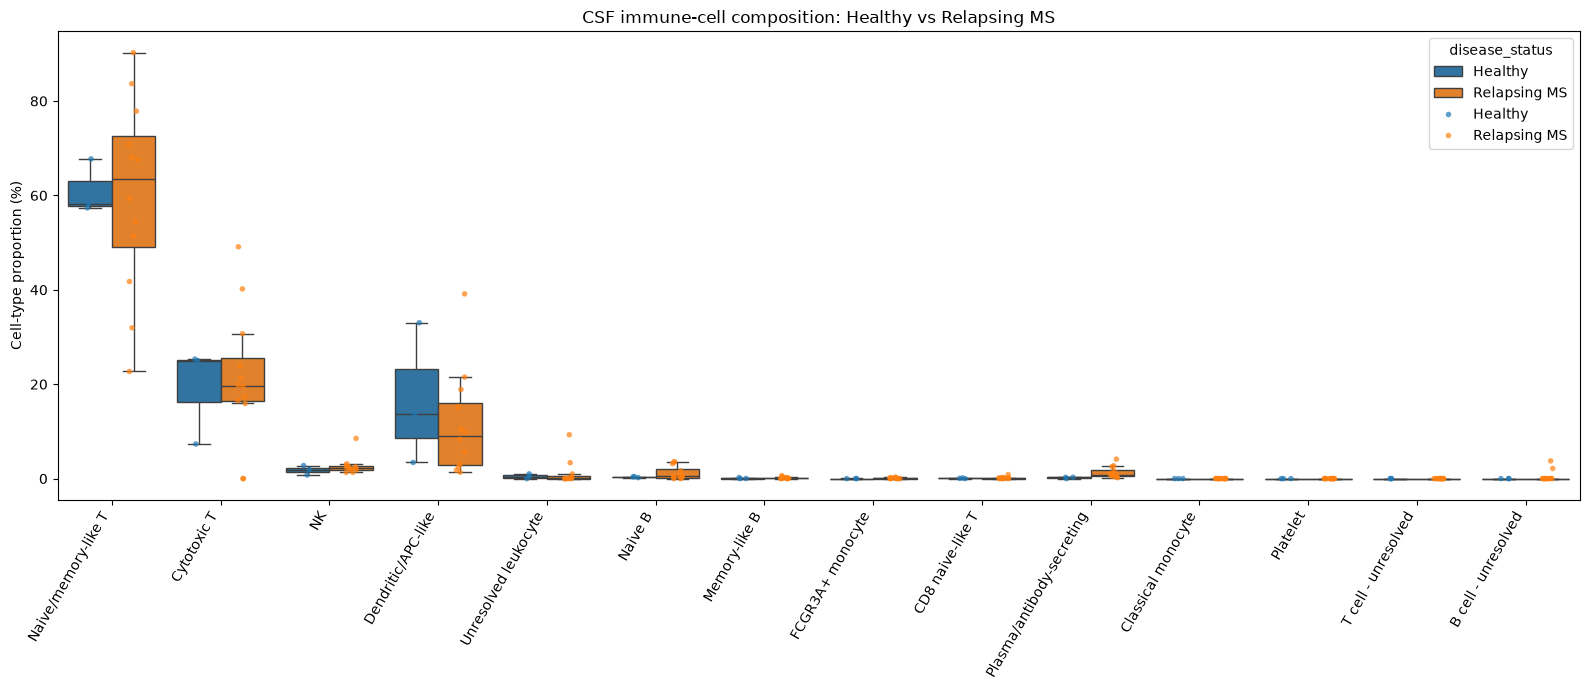

In [ ]:
plt.figure(figsize=(16, 7))

sns.boxplot(
    data=csf_comp,
    x="cell_type",
    y="percentage",
    hue="disease_status",
    showfliers=False
)

sns.stripplot(
    data=csf_comp,
    x="cell_type",
    y="percentage",
    hue="disease_status",
    dodge=True,
    alpha=0.7,
    size=4
)

plt.xticks(rotation=60, ha="right")
plt.ylabel("Cell-type proportion (%)")
plt.xlabel("")
plt.title("CSF immune-cell composition: Healthy vs Relapsing MS")

plt.tight_layout()
plt.show()

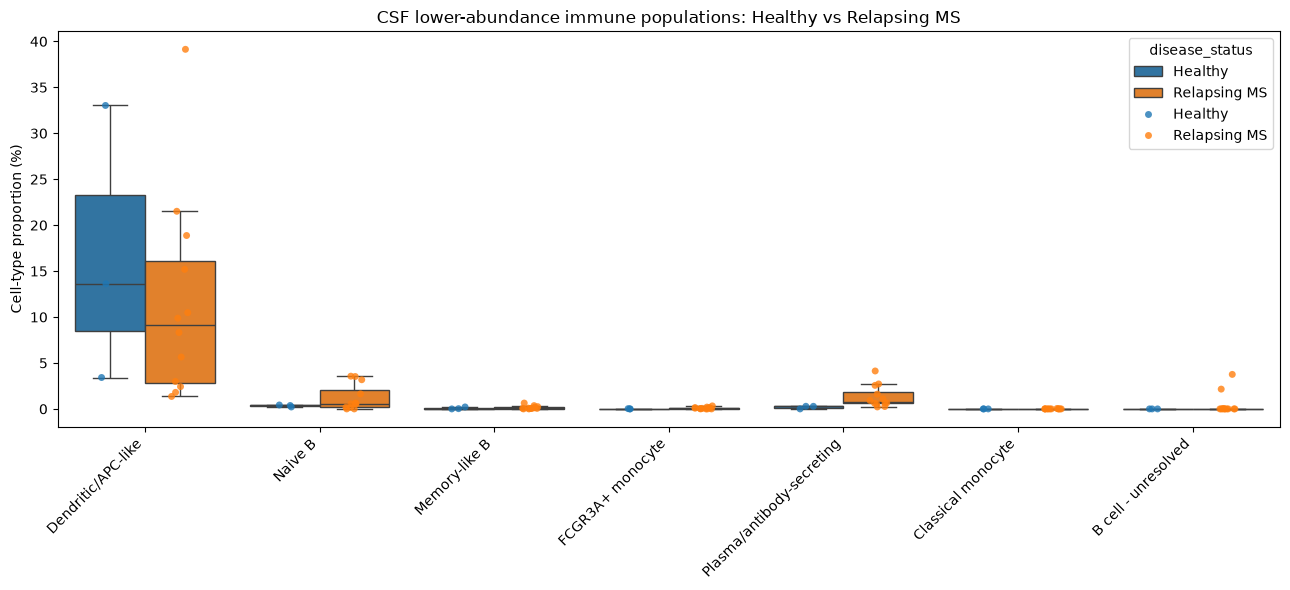

In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 4B
# Zoom in on lower-abundance CSF populations
# ============================================================
# The previous plot is dominated by T cells because some T-cell
# populations represent >50% of the sample.
#
# Here we remove the major T/NK populations temporarily from the
# visualization so that smaller B-cell and myeloid populations
# become easier to inspect.
#
# IMPORTANT:
# We are NOT removing these cells from the dataset.
# This is only a visualization subset.
# ============================================================

small_populations = [
    "Naive B",
    "Memory-like B",
    "B cell - unresolved",
    "Plasma/antibody-secreting",
    "Classical monocyte",
    "FCGR3A+ monocyte",
    "Dendritic/APC-like",
]

csf_small = csf_comp[
    csf_comp["cell_type"].isin(small_populations)
].copy()

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=csf_small,
    x="cell_type",
    y="percentage",
    hue="disease_status",
    showfliers=False
)

sns.stripplot(
    data=csf_small,
    x="cell_type",
    y="percentage",
    hue="disease_status",
    dodge=True,
    alpha=0.8,
    size=5
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Cell-type proportion (%)")
plt.xlabel("")
plt.title(
    "CSF lower-abundance immune populations: "
    "Healthy vs Relapsing MS"
)

plt.tight_layout()
plt.show()

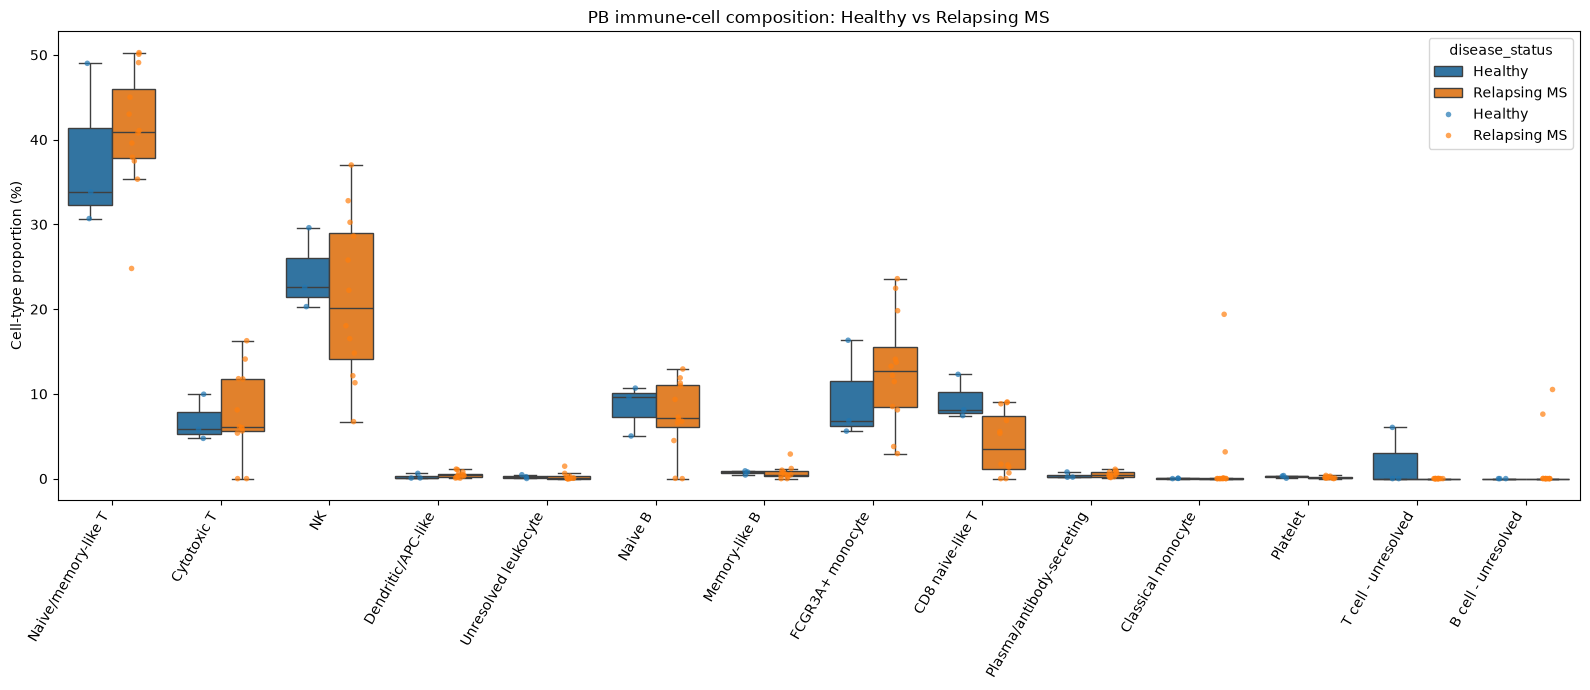

In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 5
# PB composition: Healthy vs Relapsing MS
# ============================================================
# We now repeat the same donor-level analysis in peripheral blood.
#
# This helps us distinguish:
#
#   1. Changes that may be particularly associated with CSF
#      / CNS immune environment
#
#   2. Changes that are also visible systemically in blood
#
# Each point still represents ONE DONOR.
# ============================================================

plt.figure(figsize=(16, 7))

sns.boxplot(
    data=pb_comp,
    x="cell_type",
    y="percentage",
    hue="disease_status",
    showfliers=False
)

sns.stripplot(
    data=pb_comp,
    x="cell_type",
    y="percentage",
    hue="disease_status",
    dodge=True,
    alpha=0.7,
    size=4
)

plt.xticks(rotation=60, ha="right")
plt.ylabel("Cell-type proportion (%)")
plt.xlabel("")
plt.title("PB immune-cell composition: Healthy vs Relapsing MS")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 6
# Summarize donor-level composition
# ============================================================
# Calculate the median cell-type percentage across donors.
#
# This is DESCRIPTIVE only.
# It helps us decide which populations deserve closer
# investigation.
#
# It is NOT evidence of statistical significance.
# ============================================================

composition_summary = (
    cell_composition_complete
    .groupby(
        ["compartment", "cell_type", "disease_status"],
        observed=True
    )["percentage"]
    .median()
    .unstack("disease_status")
    .reset_index()
)

composition_summary["MS_minus_Healthy"] = (
    composition_summary["Relapsing MS"]
    - composition_summary["Healthy"]
)

# Sort within compartment by absolute difference
composition_summary["abs_difference"] = (
    composition_summary["MS_minus_Healthy"].abs()
)

composition_summary = composition_summary.sort_values(
    ["compartment", "abs_difference"],
    ascending=[True, False]
)

print(
    composition_summary[
        [
            "compartment",
            "cell_type",
            "Healthy",
            "Relapsing MS",
            "MS_minus_Healthy"
        ]
    ].to_string(index=False)
)

compartment                 cell_type   Healthy  Relapsing MS  MS_minus_Healthy
        CSF               Cytotoxic T 25.000000     19.672982         -5.327018
        CSF       Naive/memory-like T 58.221595     63.430992          5.209398
        CSF        Dendritic/APC-like 13.619456      9.095248         -4.524208
        CSF Plasma/antibody-secreting  0.282287      0.783588          0.501301
        CSF                        NK  1.917024      2.317101          0.400077
        CSF      Unresolved leukocyte  0.427350      0.092894         -0.334456
        CSF                   Naive B  0.371960      0.587492          0.215532
        CSF          FCGR3A+ monocyte  0.000000      0.068171          0.068171
        CSF             Memory-like B  0.028612      0.075027          0.046415
        CSF          CD8 naive-like T  0.057225      0.092147          0.034922
        CSF       B cell - unresolved  0.000000      0.000000          0.000000
        CSF        Classical monocyte  0

In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 7
# Inspect experimental design before differential expression
# ============================================================
# Before comparing gene expression between MS and Healthy,
# we must check whether disease status is associated with
# technical or study-design variables.
#
# In particular:
#   - timepoint
#   - 3' vs 5' library chemistry
#   - compartment
#
# This prevents us from mistakenly calling a technical
# difference a disease-associated transcriptional difference.
# ============================================================

design_check = (
    adata.obs[
        adata.obs["disease_status"].isin(
            ["Healthy", "Relapsing MS"]
        )
    ][
        [
            "disease_status",
            "donor",
            "timepoint",
            "compartment",
            "library",
            "GSM"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["disease_status", "donor", "compartment", "timepoint"]
    )
)

print(design_check.to_string(index=False))

disease_status donor timepoint compartment library        GSM
       Healthy     2        t4         CSF   5pGEX GSM5264634
       Healthy     2        t4          PB   5pGEX GSM5264635
       Healthy     3        t2         CSF   5pGEX GSM5264636
       Healthy     3        t2          PB   5pGEX GSM5264637
       Healthy    32        t1         CSF   5pGEX GSM5264670
       Healthy    32        t1          PB   5pGEX GSM5264671
  Relapsing MS     6        t1         CSF   5pGEX GSM5264639
  Relapsing MS     6        t1          PB   5pGEX GSM5264640
  Relapsing MS     7        t1         CSF   5pGEX GSM5264641
  Relapsing MS     7        t1          PB   5pGEX GSM5264642
  Relapsing MS     8        t1         CSF   5pGEX GSM5264643
  Relapsing MS     8        t1          PB   5pGEX GSM5264644
  Relapsing MS     9        t1         CSF   5pGEX GSM5264645
  Relapsing MS     9        t1          PB   5pGEX GSM5264646
  Relapsing MS    10        t1         CSF   5pGEX GSM5264647
  Relaps

In [ ]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 8
# Check cell numbers per donor for each cell type
# ============================================================
# Before choosing a cell population for differential expression,
# we check whether it is sufficiently represented across donors.
#
# For pseudobulk analysis we will eventually SUM the raw UMI
# counts of cells belonging to the same donor and cell type.
#
# Therefore, populations represented by very few cells in many
# donors may produce unstable pseudobulk profiles.
# ============================================================

cell_number_check = (
    adata.obs[
        adata.obs["disease_status"].isin(
            ["Healthy", "Relapsing MS"]
        )
    ]
    .groupby(
        [
            "disease_status",
            "donor",
            "compartment",
            "cell_type"
        ],
        observed=True
    )
    .size()
    .reset_index(name="n_cells")
)

# Show CSF first
csf_cell_numbers = (
    cell_number_check[
        cell_number_check["compartment"] == "CSF"
    ]
    .pivot_table(
        index=["disease_status", "donor"],
        columns="cell_type",
        values="n_cells",
        fill_value=0
    )
)

print(csf_cell_numbers.to_string())

cell_type             B cell - unresolved  CD8 naive-like T  Classical monocyte  Cytotoxic T  Dendritic/APC-like  FCGR3A+ monocyte  Memory-like B     NK  Naive B  Naive/memory-like T  Plasma/antibody-secreting  Unresolved leukocyte
disease_status donor                                                                                                                                                                                                                   
Healthy        2                      0.0               0.0                 0.0        117.0                16.0               0.0            1.0   13.0      2.0                317.0                        0.0                   2.0
               3                      0.0               2.0                 0.0        104.0               468.0               0.0            0.0   11.0      3.0                825.0                        4.0                   0.0
               32                     0.0               2.0             

/tmp/ipykernel_255718/3806695577.py:39: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(


In [25]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 9
# Create the first pseudobulk-analysis subset
# ============================================================
# Question:
#
#   Are gene-expression programs in CSF naive/memory-like
#   T cells different between Relapsing MS and Healthy donors?
#
# PRIMARY ANALYSIS:
#   - CSF only
#   - Naive/memory-like T cells
#   - Healthy vs Relapsing MS
#   - 5pGEX libraries only
#
# Why 5p only?
# Healthy donors are all 5pGEX, whereas MS donors 16 and 18
# are 3pGEX. Restricting the primary comparison to 5p reduces
# potential confounding from library chemistry.
#
# IMPORTANT:
# Raw counts remain stored in:
#       adata.layers["counts"]
# ============================================================

tcell_csf = adata[
    (adata.obs["compartment"] == "CSF")
    & (adata.obs["cell_type"] == "Naive/memory-like T")
    & (adata.obs["disease_status"].isin(
        ["Healthy", "Relapsing MS"]
    ))
    & (adata.obs["library"] == "5pGEX")
].copy()

print(tcell_csf)

print("\nCells per donor:")
print(
    tcell_csf.obs
    .groupby(
        ["disease_status", "donor"],
        observed=True
    )
    .size()
)

KeyError: 'cell_type'

In [26]:
from pathlib import Path

data_dir = Path("../data")

print("Saved .h5ad files:")
print("=" * 40)

for f in sorted(data_dir.glob("*.h5ad")):
    print(f.name)

Saved .h5ad files:
adata_after_qc.h5ad
adata_after_qc_doublets.h5ad
adata_annotated.h5ad


In [27]:
# ============================================================
# LOAD FINAL ANNOTATED DATASET
# ============================================================
# This restores the processed single-cell dataset so we do not
# need to repeat QC, doublet detection, normalization, UMAP,
# clustering, or cell-type annotation after restarting VS Code.
# ============================================================

import scanpy as sc

adata = sc.read_h5ad("../data/adata_annotated.h5ad")

print(adata)

print("\nShape:")
print(adata.shape)

print("\nImportant metadata available:")
for col in [
    "GSM",
    "donor",
    "compartment",
    "library",
    "disease_status",
    "cell_type"
]:
    print(f"{col:15s}: {col in adata.obs.columns}")

AnnData object with n_obs × n_vars = 168077 × 33538
    obs: 'GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_0_5', 'cell_type'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'cell_type_colors', 'compartment_colors', 'dendrogram_leiden_0_5', 'hvg', 'leiden_0_5', 'leiden_0_5_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

Shape:
(168077, 33538)

Important metadata available:
GSM            : True
donor          : True
compartment    : True
library        : True
disease_status : True
cell_type      : True


In [28]:
# ============================================================
# CHECK CURRENT ANNOTATED OBJECT
# ============================================================

print("Total cells:", adata.n_obs)

print("\nCell-type counts:")
print(adata.obs["cell_type"].value_counts())

print("\nDoes a doublet column exist?")
print("predicted_doublet" in adata.obs.columns)

print("\nLayers:")
print(list(adata.layers.keys()))

print("\nRaw object available:")
print(adata.raw is not None)

Total cells: 168077

Cell-type counts:
cell_type
Naive/memory-like T          80895
NK                           28853
Cytotoxic T                  17404
FCGR3A+ monocyte             15744
Naive B                       8556
CD8 naive-like T              5001
Dendritic/APC-like            4856
Classical monocyte            1962
B cell - unresolved           1677
Plasma/antibody-secreting     1091
Memory-like B                  889
Unresolved leukocyte           696
Platelet                       228
T cell - unresolved            225
Name: count, dtype: int64

Does a doublet column exist?
False

Layers:
[]

Raw object available:
False


In [29]:
# ============================================================
# CHECK SAVED DOUBLEt-FILTERED OBJECT
# ============================================================
# Load it under a temporary name so that we do NOT overwrite
# our annotated adata object.
# ============================================================

import scanpy as sc

adata_doublet = sc.read_h5ad(
    "../data/adata_after_qc_doublets.h5ad"
)

print("Shape:")
print(adata_doublet.shape)

print("\nOBS columns:")
print(adata_doublet.obs.columns.tolist())

print("\nLayers:")
print(list(adata_doublet.layers.keys()))

print("\nRaw available:")
print(adata_doublet.raw is not None)

Shape:
(168077, 33538)

OBS columns:
['GSM', 'donor', 'timepoint', 'compartment', 'subset', 'library', 'disease_status', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt']

Layers:
[]

Raw available:
False


In [30]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 9
# Create pseudobulk-analysis subset
# ============================================================
#
# Primary exploratory comparison:
#   - CSF
#   - Naive/memory-like T cells
#   - Healthy vs Relapsing MS
#   - 5pGEX only
#
# NOTE:
# This broad T-cell population is being used as a technically
# robust pilot for the donor-level pseudobulk workflow.
# It should not yet be interpreted as the final biological
# target of the project.
# ============================================================

tcell_csf = adata[
    (adata.obs["compartment"] == "CSF")
    & (adata.obs["cell_type"] == "Naive/memory-like T")
    & (adata.obs["disease_status"].isin(
        ["Healthy", "Relapsing MS"]
    ))
    & (adata.obs["library"] == "5pGEX")
].copy()


print("Subset shape:")
print(tcell_csf.shape)

print("\nCells per donor:")
print(
    tcell_csf.obs
    .groupby(
        ["disease_status", "donor"],
        observed=True
    )
    .size()
)

Subset shape:
(17220, 33538)

Cells per donor:
disease_status  donor
Healthy         2         317
                3         825
                32       2005
Relapsing MS    6         688
                7        1815
                8        2324
                9        1757
                10       1301
                24       2435
                25       1224
                27        710
                28       1641
                29        178
dtype: int64


In [31]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 10
# Locate original raw UMI-count files
# ============================================================
#
# WHY?
# The saved annotated AnnData object contains normalized/log-
# transformed expression values, but the raw UMI-count layer
# was not preserved.
#
# For pseudobulk analysis we need RAW INTEGER COUNTS.
#
# Therefore, we recover counts for the selected 17,220 cells
# directly from the original GEO rawCounts files.
# ============================================================

from pathlib import Path

raw_dir = Path("../data/raw_counts")

raw_files = sorted(
    raw_dir.glob("*.rawCounts.csv.gz")
)

print("Raw-count directory:")
print(raw_dir.resolve())

print("\nNumber of raw-count files:")
print(len(raw_files))

print("\nFirst 5 files:")
for f in raw_files[:5]:
    print(f.name)

Raw-count directory:
/home/operation/github/single-cell-disease-pipeline/data/raw_counts

Number of raw-count files:
38

First 5 files:
GSM5264634_2_t4_CSF_uns_5pGEX.rawCounts.csv.gz
GSM5264635_2_t4_PB_uns_5pGEX.rawCounts.csv.gz
GSM5264636_3_t2_CSF_uns_5pGEX.rawCounts.csv.gz
GSM5264637_3_t2_PB_uns_5pGEX.rawCounts.csv.gz
GSM5264638_5_t1_PB_uns_5pGEX.rawCounts.csv.gz


In [32]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 11
# Recover raw UMI counts for the selected 17,220 cells
# ============================================================
#
# WHY?
# tcell_csf.X contains normalized/log-transformed expression.
# Pseudobulk count-based differential expression requires
# original raw UMI counts.
#
# We therefore:
#   1. identify which GSM samples occur in tcell_csf
#   2. find the corresponding GEO rawCounts file
#   3. read only the selected cell barcodes
#   4. preserve the gene order of tcell_csf.var_names
#   5. combine the recovered counts
#
# IMPORTANT:
# We do NOT modify the original GEO files.
# ============================================================

import pandas as pd
import numpy as np
import scipy.sparse as sp


# ------------------------------------------------------------
# 1. Build GSM -> raw file lookup
# ------------------------------------------------------------

gsm_to_file = {}

for file in raw_files:
    gsm = file.name.split("_")[0]
    gsm_to_file[gsm] = file


# ------------------------------------------------------------
# 2. Check which GSM samples are represented in our subset
# ------------------------------------------------------------

selected_gsms = sorted(
    tcell_csf.obs["GSM"].astype(str).unique()
)

print("Number of GSM samples in subset:")
print(len(selected_gsms))

print("\nSelected GSMs:")
print(selected_gsms)


# ------------------------------------------------------------
# 3. Make sure every selected GSM has a raw-count file
# ------------------------------------------------------------

missing_gsms = [
    gsm for gsm in selected_gsms
    if gsm not in gsm_to_file
]

print("\nMissing raw files:")
print(missing_gsms)

if missing_gsms:
    raise ValueError(
        f"Raw-count files missing for: {missing_gsms}"
    )


# ------------------------------------------------------------
# 4. Recover raw counts sample by sample
# ------------------------------------------------------------

recovered_blocks = []
recovered_cell_ids = []

genes = tcell_csf.var_names.astype(str)

for gsm in selected_gsms:

    file = gsm_to_file[gsm]

    # Cells belonging to this GSM
    sample_cells = tcell_csf.obs_names[
        tcell_csf.obs["GSM"].astype(str) == gsm
    ]

    # Our AnnData cell names were made unique during concatenation.
    # The original barcode is the part before the final "-GSM..."
    # Rather than assuming the suffix structure, match using the
    # original barcode stored at the beginning of the obs name.

    original_barcodes = [
        cell_id.split("-" + gsm)[0]
        for cell_id in sample_cells
    ]

    print(
        f"\n{gsm}: recovering {len(sample_cells)} cells "
        f"from {file.name}"
    )

    # Read raw gene x cell matrix
    raw_df = pd.read_csv(
        file,
        index_col=0,
        compression="gzip"
    )

    # Check genes
    missing_genes = genes.difference(raw_df.index)

    if len(missing_genes) > 0:
        raise ValueError(
            f"{gsm}: {len(missing_genes)} genes are missing "
            "from the raw matrix."
        )

    # Check cell barcodes
    missing_cells = [
        bc for bc in original_barcodes
        if bc not in raw_df.columns
    ]

    if missing_cells:
        raise ValueError(
            f"{gsm}: {len(missing_cells)} selected cells "
            "could not be found in the raw matrix."
        )

    # Select genes + cells and transpose:
    # genes x cells  ->  cells x genes
    block = (
        raw_df
        .loc[genes, original_barcodes]
        .T
        .to_numpy()
    )

    recovered_blocks.append(
        sp.csr_matrix(block)
    )

    recovered_cell_ids.extend(sample_cells.tolist())


# ------------------------------------------------------------
# 5. Combine all recovered samples
# ------------------------------------------------------------

raw_recovered = sp.vstack(
    recovered_blocks,
    format="csr"
)

print("\n========================================")
print("RAW COUNT RECOVERY FINISHED")
print("========================================")

print("Recovered matrix shape:")
print(raw_recovered.shape)

print("\nExpected shape:")
print(tcell_csf.shape)

print("\nNumber of recovered cell IDs:")
print(len(recovered_cell_ids))

Number of GSM samples in subset:
13

Selected GSMs:
['GSM5264634', 'GSM5264636', 'GSM5264639', 'GSM5264641', 'GSM5264643', 'GSM5264645', 'GSM5264647', 'GSM5264657', 'GSM5264659', 'GSM5264661', 'GSM5264663', 'GSM5264665', 'GSM5264670']

Missing raw files:
[]

GSM5264634: recovering 317 cells from GSM5264634_2_t4_CSF_uns_5pGEX.rawCounts.csv.gz

GSM5264636: recovering 825 cells from GSM5264636_3_t2_CSF_uns_5pGEX.rawCounts.csv.gz

GSM5264639: recovering 688 cells from GSM5264639_6_t1_CSF_uns_5pGEX.rawCounts.csv.gz

GSM5264641: recovering 1815 cells from GSM5264641_7_t1_CSF_uns_5pGEX.rawCounts.csv.gz

GSM5264643: recovering 2324 cells from GSM5264643_8_t1_CSF_uns_5pGEX.rawCounts.csv.gz

GSM5264645: recovering 1757 cells from GSM5264645_9_t1_CSF_uns_5pGEX_2.rawCounts.csv.gz

GSM5264647: recovering 1301 cells from GSM5264647_10_t1_CSF_uns_5pGEX.rawCounts.csv.gz

GSM5264657: recovering 2435 cells from GSM5264657_24_t2_CSF_uns_5pGEX.rawCounts.csv.gz

GSM5264659: recovering 1224 cells from GSM52

In [33]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 11B
# Validate recovered raw UMI counts
# ============================================================
#
# Before pseudobulk aggregation we verify:
#
#   1. recovered matrix has the expected dimensions
#   2. recovered cells are in exactly the same order as
#      tcell_csf.obs_names
#   3. no selected cell has zero total counts
#   4. recovered non-zero values are integer-like
#   5. inspect per-cell raw UMI totals
#
# We do NOT aggregate until these checks pass.
# ============================================================


# ------------------------------------------------------------
# 1. Shape check
# ------------------------------------------------------------

print("Recovered shape:")
print(raw_recovered.shape)

print("\nExpected shape:")
print(tcell_csf.shape)

print(
    "\nShape matches:",
    raw_recovered.shape == tcell_csf.shape
)


# ------------------------------------------------------------
# 2. Cell-order check
# ------------------------------------------------------------

cell_order_matches = np.array_equal(
    np.asarray(recovered_cell_ids, dtype=str),
    tcell_csf.obs_names.astype(str).to_numpy()
)

print("\nCell order matches tcell_csf:")
print(cell_order_matches)


# ------------------------------------------------------------
# 3. Raw UMI totals per cell
# ------------------------------------------------------------

cell_totals = np.asarray(
    raw_recovered.sum(axis=1)
).ravel()

print("\nPer-cell raw UMI totals:")

print("Minimum:", cell_totals.min())
print("Median :", np.median(cell_totals))
print("Maximum:", cell_totals.max())

print(
    "Cells with zero total counts:",
    np.sum(cell_totals == 0)
)


# ------------------------------------------------------------
# 4. Check whether non-zero counts are integer-like
# ------------------------------------------------------------

nonzero_values = raw_recovered.data

integer_like = np.allclose(
    nonzero_values,
    np.round(nonzero_values)
)

print("\nAll non-zero counts integer-like:")
print(integer_like)


# ------------------------------------------------------------
# 5. Overall raw-count total
# ------------------------------------------------------------

print("\nTotal recovered UMI counts:")
print(raw_recovered.sum())

Recovered shape:
(17220, 33538)

Expected shape:
(17220, 33538)

Shape matches: True

Cell order matches tcell_csf:
True

Per-cell raw UMI totals:
Minimum: 1097
Median : 2645.0
Maximum: 9142
Cells with zero total counts: 0

All non-zero counts integer-like:
True

Total recovered UMI counts:
49071003


In [34]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 11C
# Aggregate raw UMI counts into donor-level pseudobulk samples
# ============================================================
#
# WHY PSEUDOBULK?
#
# Individual cells are NOT independent biological replicates.
# The biological replicate in this comparison is the DONOR.
#
# Therefore, for each donor we sum raw UMI counts across all
# selected CSF naive/memory-like T cells.
#
# Result:
#       17,220 cells
#             ↓
#       13 donor samples
#             ↓
#       3 Healthy + 10 Relapsing MS
#
# These donor-level count profiles can later be used for
# count-based differential-expression analysis.
# ============================================================

import pandas as pd
import numpy as np
import scipy.sparse as sp


# ------------------------------------------------------------
# 1. Identify donors
# ------------------------------------------------------------

donors = sorted(
    tcell_csf.obs["donor"].astype(str).unique(),
    key=lambda x: int(x)
)

print("Donors:")
print(donors)

print("\nNumber of donors:")
print(len(donors))


# ------------------------------------------------------------
# 2. Aggregate raw counts donor by donor
# ------------------------------------------------------------

pseudobulk_blocks = []
metadata_records = []

donor_array = tcell_csf.obs["donor"].astype(str).to_numpy()

for donor in donors:

    # Integer positions of cells belonging to this donor
    positions = np.where(donor_array == donor)[0]

    # Sum raw UMI counts across those cells
    donor_counts = np.asarray(
        raw_recovered[positions, :].sum(axis=0)
    ).ravel()

    pseudobulk_blocks.append(donor_counts)

    # Metadata are identical within this selected donor subset
    donor_obs = tcell_csf.obs.iloc[positions]

    metadata_records.append({
        "donor": donor,
        "disease_status": donor_obs["disease_status"].iloc[0],
        "compartment": donor_obs["compartment"].iloc[0],
        "library": donor_obs["library"].iloc[0],
        "n_cells": len(positions),
        "library_size": int(donor_counts.sum()),
        "detected_genes": int(np.sum(donor_counts > 0))
    })


# ------------------------------------------------------------
# 3. Construct pseudobulk count matrix
# ------------------------------------------------------------

pseudobulk_counts = pd.DataFrame(
    np.vstack(pseudobulk_blocks),
    index=donors,
    columns=tcell_csf.var_names
)

pseudobulk_counts.index.name = "donor"


# ------------------------------------------------------------
# 4. Construct pseudobulk metadata
# ------------------------------------------------------------

pseudobulk_meta = pd.DataFrame(
    metadata_records
).set_index("donor")


# ------------------------------------------------------------
# 5. Validate
# ------------------------------------------------------------

print("\nPseudobulk matrix shape:")
print(pseudobulk_counts.shape)

print("\nPseudobulk metadata:")
print(pseudobulk_meta)

print("\nDisease groups:")
print(pseudobulk_meta["disease_status"].value_counts())

print("\nAll counts integer-like:")
print(
    np.allclose(
        pseudobulk_counts.values,
        np.round(pseudobulk_counts.values)
    )
)

print("\nTotal pseudobulk counts:")
print(pseudobulk_counts.values.sum())

print("\nOriginal recovered raw counts:")
print(raw_recovered.sum())

print(
    "\nTotals match:",
    np.isclose(
        pseudobulk_counts.values.sum(),
        raw_recovered.sum()
    )
)

Donors:
['2', '3', '6', '7', '8', '9', '10', '24', '25', '27', '28', '29', '32']

Number of donors:
13

Pseudobulk matrix shape:
(13, 33538)

Pseudobulk metadata:
      disease_status compartment library  n_cells  library_size  \
donor                                                             
2            Healthy         CSF   5pGEX      317       1126403   
3            Healthy         CSF   5pGEX      825       1875501   
6       Relapsing MS         CSF   5pGEX      688       2432046   
7       Relapsing MS         CSF   5pGEX     1815       5565725   
8       Relapsing MS         CSF   5pGEX     2324       6660749   
9       Relapsing MS         CSF   5pGEX     1757       5779197   
10      Relapsing MS         CSF   5pGEX     1301       4479781   
24      Relapsing MS         CSF   5pGEX     2435       5713630   
25      Relapsing MS         CSF   5pGEX     1224       2960286   
27      Relapsing MS         CSF   5pGEX      710       1770377   
28      Relapsing MS         CSF 

In [35]:
# ============================================================
# BIOLOGICAL ANALYSIS — STEP 11D
# Save donor-level pseudobulk data
# ============================================================
#
# This creates a permanent restart point.
# Next time VS Code/Jupyter is restarted, we can load these
# two files directly and continue with pseudobulk QC,
# filtering, PCA and differential-expression analysis.
# ============================================================

from pathlib import Path

output_dir = Path("../data/pseudobulk")
output_dir.mkdir(parents=True, exist_ok=True)

counts_file = (
    output_dir /
    "tcell_csf_5p_pseudobulk_counts.csv.gz"
)

metadata_file = (
    output_dir /
    "tcell_csf_5p_pseudobulk_metadata.csv"
)

pseudobulk_counts.to_csv(
    counts_file,
    compression="gzip"
)

pseudobulk_meta.to_csv(
    metadata_file
)

print("Saved pseudobulk counts:")
print(counts_file.resolve())

print("\nSaved pseudobulk metadata:")
print(metadata_file.resolve())

print("\nFiles exist:")
print("Counts:", counts_file.exists())
print("Metadata:", metadata_file.exists())

Saved pseudobulk counts:
/home/operation/github/single-cell-disease-pipeline/data/pseudobulk/tcell_csf_5p_pseudobulk_counts.csv.gz

Saved pseudobulk metadata:
/home/operation/github/single-cell-disease-pipeline/data/pseudobulk/tcell_csf_5p_pseudobulk_metadata.csv

Files exist:
Counts: True
Metadata: True


,disease_status,n_cells,library_size,detected_genes
donor,,,,
2,Healthy,317,1126403,12716
3,Healthy,825,1875501,13545
6,Relapsing MS,688,2432046,15091
7,Relapsing MS,1815,5565725,16490
8,Relapsing MS,2324,6660749,15428
9,Relapsing MS,1757,5779197,16096
10,Relapsing MS,1301,4479781,14341
24,Relapsing MS,2435,5713630,16367
25,Relapsing MS,1224,2960286,14748



Number of biological replicates:
13

Disease groups:
disease_status
Relapsing MS    10
Healthy          3
Name: count, dtype: int64

Library-size range:
426,083 to 6,878,483

Detected-gene range:
11,117 to 16,490


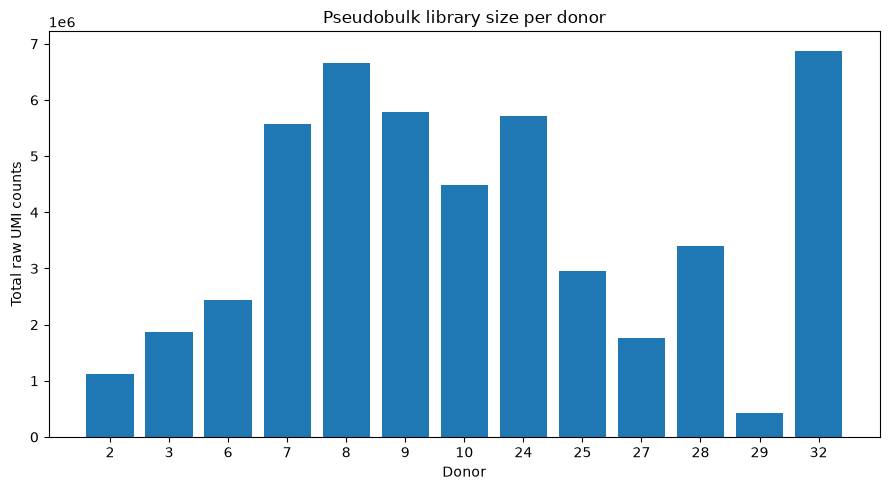

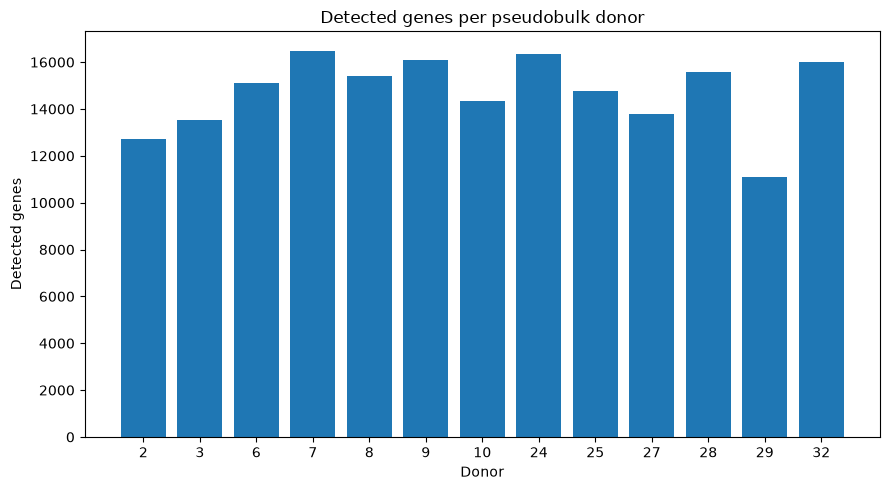

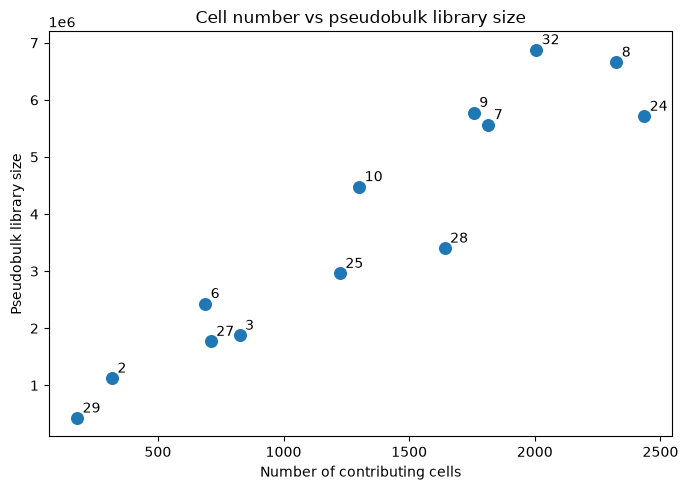

In [36]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 12: Donor-level pseudobulk quality control
# ============================================================
#
# PURPOSE
# -------
# We have aggregated raw UMI counts from individual cells into
# donor-level pseudobulk samples.
#
# The DONOR is the biological replicate for the MS vs Healthy
# comparison.
#
# Before differential-expression analysis, we inspect:
#
#   1. n_cells        -> cells contributing to each pseudobulk
#   2. library_size   -> total raw UMI counts
#   3. detected_genes -> genes with at least one count
#
# IMPORTANT:
# A donor with fewer cells or lower sequencing depth is not
# automatically a bad sample. We inspect the data first and
# later use sensitivity analysis if necessary.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Calculate number of detected genes per donor
# ------------------------------------------------------------

pseudobulk_meta["detected_genes"] = (
    pseudobulk_counts > 0
).sum(axis=1)


# ------------------------------------------------------------
# 2. Create QC table
# ------------------------------------------------------------

qc_table = pseudobulk_meta[
    [
        "disease_status",
        "n_cells",
        "library_size",
        "detected_genes"
    ]
].copy()

display(qc_table)


# ------------------------------------------------------------
# 3. Basic summary
# ------------------------------------------------------------

print("\nNumber of biological replicates:")
print(len(qc_table))

print("\nDisease groups:")
print(qc_table["disease_status"].value_counts())

print("\nLibrary-size range:")
print(
    f"{qc_table['library_size'].min():,}",
    "to",
    f"{qc_table['library_size'].max():,}"
)

print("\nDetected-gene range:")
print(
    f"{qc_table['detected_genes'].min():,}",
    "to",
    f"{qc_table['detected_genes'].max():,}"
)


# ------------------------------------------------------------
# 4. Visualize library size
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    qc_table.index.astype(str),
    qc_table["library_size"]
)

plt.xlabel("Donor")
plt.ylabel("Total raw UMI counts")
plt.title("Pseudobulk library size per donor")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Visualize detected genes
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    qc_table.index.astype(str),
    qc_table["detected_genes"]
)

plt.xlabel("Donor")
plt.ylabel("Detected genes")
plt.title("Detected genes per pseudobulk donor")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Relationship between cell number and sequencing depth
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    qc_table["n_cells"],
    qc_table["library_size"],
    s=70
)

for donor, row in qc_table.iterrows():
    plt.annotate(
        str(donor),
        (row["n_cells"], row["library_size"]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("Number of contributing cells")
plt.ylabel("Pseudobulk library size")
plt.title("Cell number vs pseudobulk library size")

plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 13: Filter low-expression genes
# ============================================================
#
# PURPOSE
# -------
# The pseudobulk matrix contains 33,538 genes, but many genes
# have very few or zero counts across most donors.
#
# Testing extremely low-expression genes:
#
#   • provides little statistical information
#   • increases the multiple-testing burden
#   • can produce unstable effect-size estimates
#
# For this exploratory analysis, we retain genes that have:
#
#       >= 10 raw counts
#
# in at least:
#
#       3 donors
#
# Why 3 donors?
# The smaller biological group contains 3 Healthy donors.
#
# This is a pragmatic filtering rule for our workflow.
# It is NOT a universal RNA-seq threshold. The final DE method
# may also provide its own expression/filtering procedure.
# ============================================================


# ------------------------------------------------------------
# 1. Count how many donors have >=10 counts for each gene
# ------------------------------------------------------------

donors_with_expression = (
    pseudobulk_counts >= 10
).sum(axis=0)


# ------------------------------------------------------------
# 2. Define filtering rule
# ------------------------------------------------------------

keep_genes = donors_with_expression >= 3


# ------------------------------------------------------------
# 3. Apply filtering
# ------------------------------------------------------------

pseudobulk_counts_filtered = (
    pseudobulk_counts.loc[:, keep_genes].copy()
)


# ------------------------------------------------------------
# 4. Summarize filtering
# ------------------------------------------------------------

n_before = pseudobulk_counts.shape[1]
n_after = pseudobulk_counts_filtered.shape[1]
n_removed = n_before - n_after

print("Genes before filtering:")
print(n_before)

print("\nGenes retained:")
print(n_after)

print("\nGenes removed:")
print(n_removed)

print(
    "\nPercentage retained:",
    round(n_after / n_before * 100, 1),
    "%"
)

print("\nFiltered matrix shape:")
print(pseudobulk_counts_filtered.shape)


# ------------------------------------------------------------
# 5. Examine the most abundant genes
# ------------------------------------------------------------

gene_totals = (
    pseudobulk_counts_filtered
    .sum(axis=0)
    .sort_values(ascending=False)
)

print("\nTop 20 genes by total raw counts:")
display(gene_totals.head(20))

Genes before filtering:
33538

Genes retained:
11371

Genes removed:
22167

Percentage retained: 33.9 %

Filtered matrix shape:
(13, 11371)

Top 20 genes by total raw counts:


MALAT1    1328067
EEF1A1     912646
RPL41      815328
RPS27      771388
RPL10      666376
RPS12      612999
RPLP1      530364
RPL30      527345
RPL39      513345
RPL13      511762
B2M        484540
RPL32      454996
RPS15A     454554
RPS28      448360
MT-CO2     436502
RPL34      424820
RPS18      419311
RPL11      414763
RPL28      402456
RPS3       401648
dtype: int64

PCA input shape:
(13, 3000)

Variance explained:
PC1: 31.74 %
PC2: 18.99 %


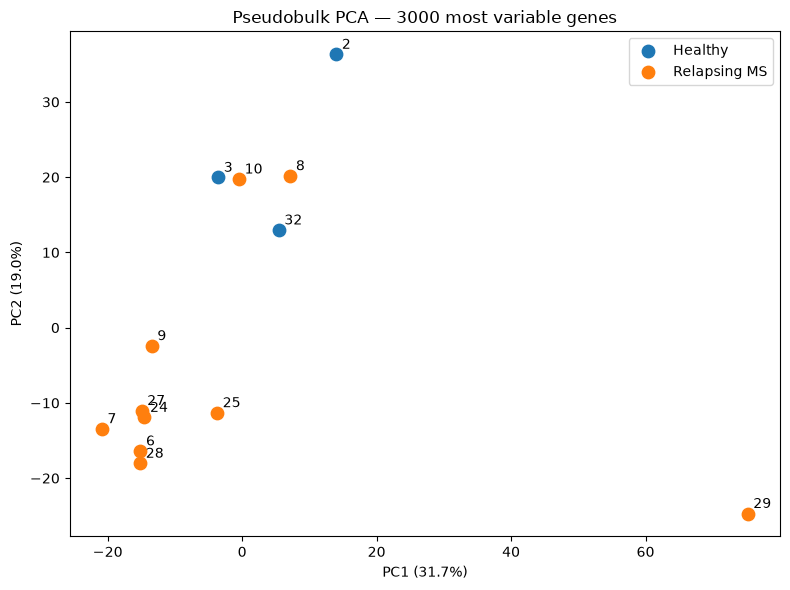

In [38]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 14: Exploratory pseudobulk PCA
# ============================================================
#
# PURPOSE
# -------
# Before differential expression, examine whether the 13
# donor-level expression profiles show unusual structure.
#
# PCA can help us detect:
#
#   • potential outlier donors
#   • large technical effects
#   • broad disease-associated structure
#
# IMPORTANT:
# PCA is exploratory.
#
# Separation between Healthy and MS would NOT prove a disease
# effect, and lack of separation would NOT mean that there are
# no disease-associated genes.
#
# For visualization only:
#
# raw counts
#     ↓
# counts per million (CPM)
#     ↓
# log2(CPM + 1)
#     ↓
# 3000 most variable genes
#     ↓
# PCA
#
# Raw counts remain unchanged for later count-based DE.
# ============================================================

from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Calculate library sizes AFTER gene filtering
# ------------------------------------------------------------

filtered_library_sizes = (
    pseudobulk_counts_filtered.sum(axis=1)
)


# ------------------------------------------------------------
# 2. Convert raw counts to CPM
# ------------------------------------------------------------

pseudobulk_cpm = (
    pseudobulk_counts_filtered
    .div(filtered_library_sizes, axis=0)
    * 1_000_000
)


# ------------------------------------------------------------
# 3. Log-transform CPM
# ------------------------------------------------------------

pseudobulk_logcpm = np.log2(
    pseudobulk_cpm + 1
)


# ------------------------------------------------------------
# 4. Select 3000 most variable genes
# ------------------------------------------------------------

gene_variance = pseudobulk_logcpm.var(axis=0)

top_variable_genes = (
    gene_variance
    .sort_values(ascending=False)
    .head(3000)
    .index
)

pca_input = pseudobulk_logcpm[
    top_variable_genes
]


print("PCA input shape:")
print(pca_input.shape)


# ------------------------------------------------------------
# 5. PCA
# ------------------------------------------------------------

pca = PCA(n_components=5)

pca_coordinates = pca.fit_transform(
    pca_input
)


# ------------------------------------------------------------
# 6. Store coordinates with donor metadata
# ------------------------------------------------------------

pca_results = pseudobulk_meta.copy()

pca_results["PC1"] = pca_coordinates[:, 0]
pca_results["PC2"] = pca_coordinates[:, 1]


print("\nVariance explained:")

print(
    "PC1:",
    round(
        pca.explained_variance_ratio_[0] * 100,
        2
    ),
    "%"
)

print(
    "PC2:",
    round(
        pca.explained_variance_ratio_[1] * 100,
        2
    ),
    "%"
)


# ------------------------------------------------------------
# 7. Plot donors
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

for disease in ["Healthy", "Relapsing MS"]:

    subset = pca_results[
        pca_results["disease_status"] == disease
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=disease,
        s=80
    )


# Label every donor
for donor, row in pca_results.iterrows():

    plt.annotate(
        str(donor),
        (row["PC1"], row["PC2"]),
        xytext=(4, 4),
        textcoords="offset points"
    )


plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title(
    "Pseudobulk PCA — 3000 most variable genes"
)

plt.legend()

plt.tight_layout()
plt.show()

Correlation with technical variables:

n_cells         PC1 = -0.475   PC2 =  0.012
library_size    PC1 = -0.423   PC2 =  0.136
detected_genes  PC1 = -0.772   PC2 = -0.114


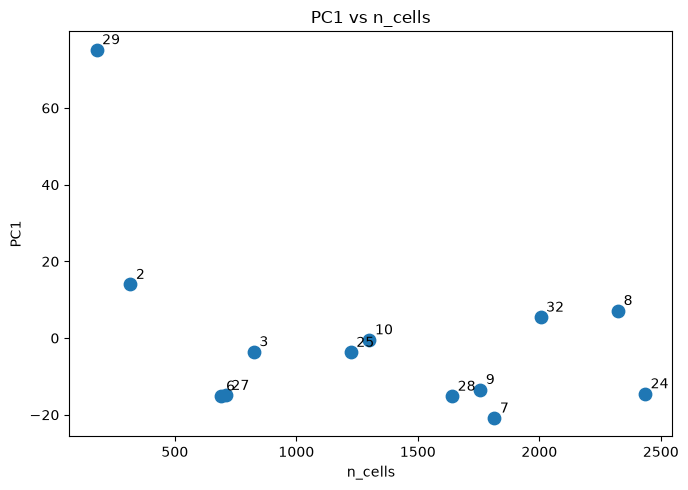

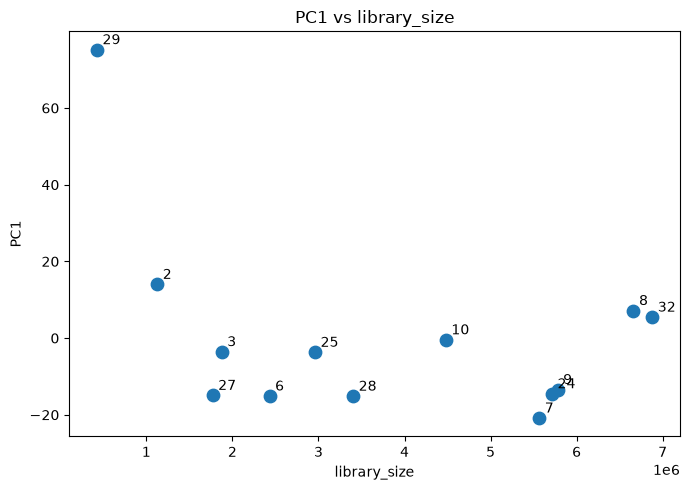

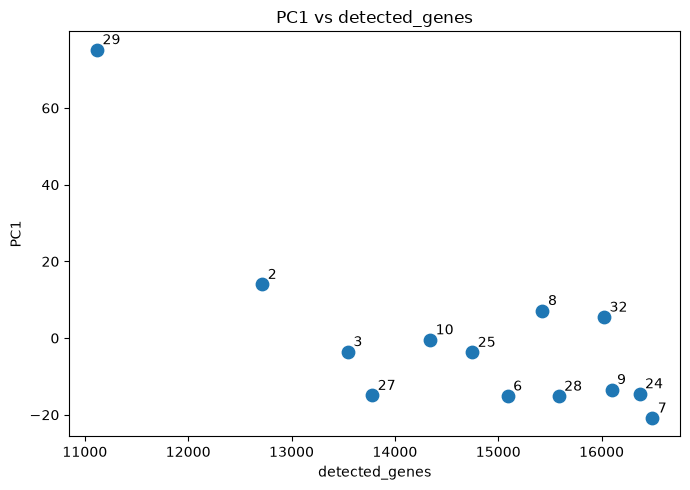

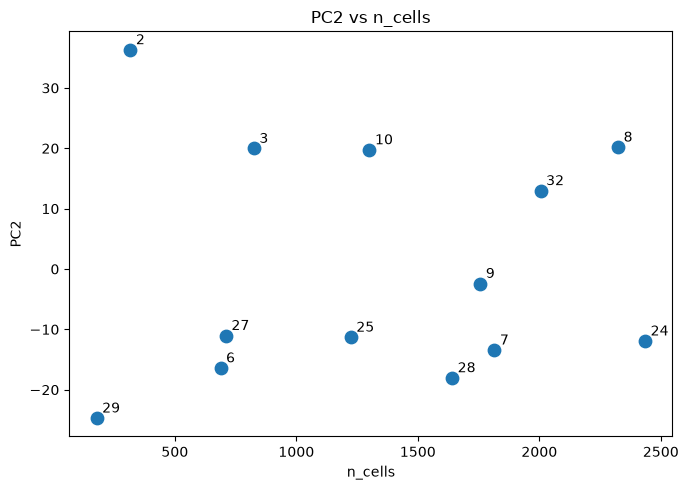

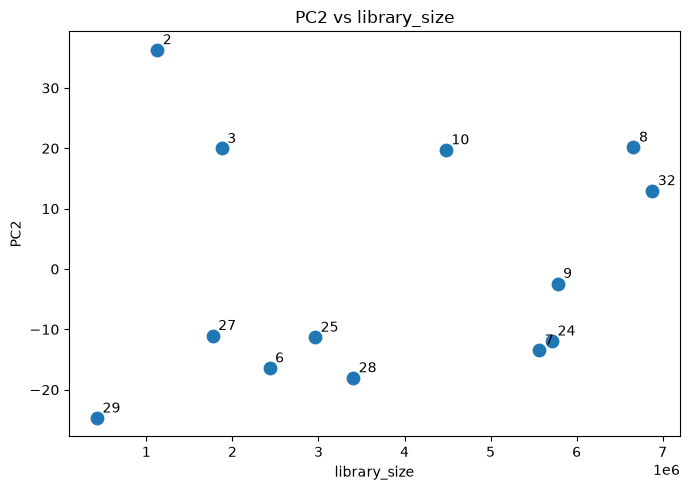

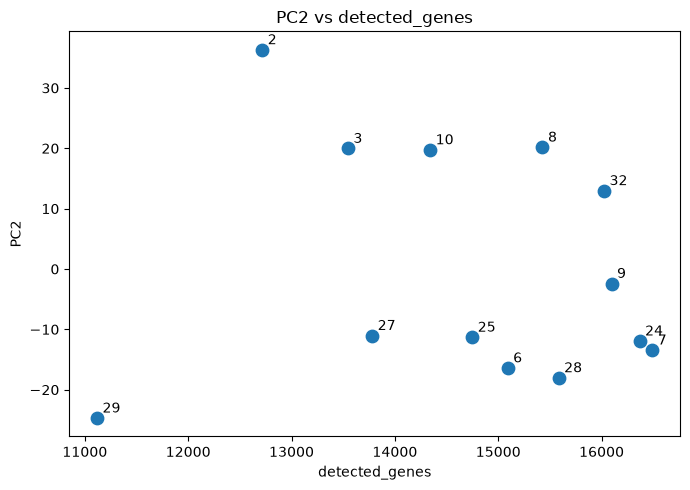

In [39]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 15: Assess technical contributions to PCA structure
# ============================================================
#
# PURPOSE
# -------
# PCA revealed substantial donor-to-donor variation:
#
#   PC1 = 31.7%
#   PC2 = 19.0%
#
# Donor 29 appears particularly unusual on PC1, and some
# disease-associated structure appears along PC2.
#
# However, before interpreting these patterns biologically,
# we need to ask whether PC1/PC2 are associated with basic
# technical properties of the pseudobulk samples:
#
#   • number of contributing cells
#   • library size
#   • number of detected genes
#
# IMPORTANT:
# Correlation does NOT prove that a PC is "technical".
# These variables are themselves related to one another and
# may also reflect biological differences.
#
# This is a diagnostic step, not an exclusion rule.
# ============================================================


# ------------------------------------------------------------
# 1. Add QC variables to PCA results
# ------------------------------------------------------------

pca_check = pca_results.copy()

technical_variables = [
    "n_cells",
    "library_size",
    "detected_genes"
]


# ------------------------------------------------------------
# 2. Calculate correlations with PC1 and PC2
# ------------------------------------------------------------

print("Correlation with technical variables:\n")

for variable in technical_variables:

    pc1_corr = pca_check["PC1"].corr(
        pca_check[variable]
    )

    pc2_corr = pca_check["PC2"].corr(
        pca_check[variable]
    )

    print(
        f"{variable:15s} "
        f"PC1 = {pc1_corr: .3f}   "
        f"PC2 = {pc2_corr: .3f}"
    )


# ------------------------------------------------------------
# 3. Plot PC1 against each technical variable
# ------------------------------------------------------------

for variable in technical_variables:

    plt.figure(figsize=(7, 5))

    plt.scatter(
        pca_check[variable],
        pca_check["PC1"],
        s=80
    )

    for donor, row in pca_check.iterrows():

        plt.annotate(
            str(donor),
            (row[variable], row["PC1"]),
            xytext=(4, 4),
            textcoords="offset points"
        )

    plt.xlabel(variable)
    plt.ylabel("PC1")

    plt.title(
        f"PC1 vs {variable}"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 4. Plot PC2 against each technical variable
# ------------------------------------------------------------

for variable in technical_variables:

    plt.figure(figsize=(7, 5))

    plt.scatter(
        pca_check[variable],
        pca_check["PC2"],
        s=80
    )

    for donor, row in pca_check.iterrows():

        plt.annotate(
            str(donor),
            (row[variable], row["PC2"]),
            xytext=(4, 4),
            textcoords="offset points"
        )

    plt.xlabel(variable)
    plt.ylabel("PC2")

    plt.title(
        f"PC2 vs {variable}"
    )

    plt.tight_layout()
    plt.show()

In [40]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 16: Final design check before differential expression
# ============================================================
#
# BIOLOGICAL QUESTION
# -------------------
# Within the broad "Naive/memory-like T" population in CSF,
# which genes show different donor-level expression between:
#
#       Relapsing MS vs Healthy
#
# DESIGN
# ------
# Biological replicate = donor
#
# Primary analysis:
#       10 Relapsing MS donors
#        3 Healthy donors
#
# All selected samples:
#       compartment = CSF
#       library     = 5pGEX
#
# Donor 29 remains INCLUDED.
# Later we will repeat the analysis without donor 29 as a
# sensitivity analysis.
#
# IMPORTANT
# ---------
# This is a demonstration population for our donor-aware
# pipeline. We are not claiming that this broad T-cell
# population represents a novel MS cell state.
# ============================================================


# ------------------------------------------------------------
# 1. Display complete DE metadata
# ------------------------------------------------------------

design_table = pseudobulk_meta[
    [
        "disease_status",
        "compartment",
        "library",
        "n_cells",
        "library_size",
        "detected_genes"
    ]
].copy()

display(design_table)


# ------------------------------------------------------------
# 2. Verify disease groups
# ------------------------------------------------------------

print("Disease groups:")
print(
    design_table["disease_status"].value_counts()
)


# ------------------------------------------------------------
# 3. Verify compartment
# ------------------------------------------------------------

print("\nCompartments:")
print(
    design_table["compartment"].value_counts()
)


# ------------------------------------------------------------
# 4. Verify sequencing chemistry
# ------------------------------------------------------------

print("\nLibraries:")
print(
    design_table["library"].value_counts()
)


# ------------------------------------------------------------
# 5. Verify filtered raw-count matrix
# ------------------------------------------------------------

print("\nFiltered count matrix:")
print(
    pseudobulk_counts_filtered.shape
)


# ------------------------------------------------------------
# 6. Confirm donor ordering matches count matrix
# ------------------------------------------------------------

metadata_donors = design_table.index.astype(str).tolist()
count_donors = (
    pseudobulk_counts_filtered.index
    .astype(str)
    .tolist()
)

print(
    "\nMetadata/count donor order identical:",
    metadata_donors == count_donors
)


# ------------------------------------------------------------
# 7. Confirm raw counts are still integer-like
# ------------------------------------------------------------

print(
    "Counts integer-like:",
    np.allclose(
        pseudobulk_counts_filtered.values,
        np.round(pseudobulk_counts_filtered.values)
    )
)

,disease_status,compartment,library,n_cells,library_size,detected_genes
donor,,,,,,
2,Healthy,CSF,5pGEX,317,1126403,12716
3,Healthy,CSF,5pGEX,825,1875501,13545
6,Relapsing MS,CSF,5pGEX,688,2432046,15091
7,Relapsing MS,CSF,5pGEX,1815,5565725,16490
8,Relapsing MS,CSF,5pGEX,2324,6660749,15428
9,Relapsing MS,CSF,5pGEX,1757,5779197,16096
10,Relapsing MS,CSF,5pGEX,1301,4479781,14341
24,Relapsing MS,CSF,5pGEX,2435,5713630,16367
25,Relapsing MS,CSF,5pGEX,1224,2960286,14748


Disease groups:
disease_status
Relapsing MS    10
Healthy          3
Name: count, dtype: int64

Compartments:
compartment
CSF    13
Name: count, dtype: int64

Libraries:
library
5pGEX    13
Name: count, dtype: int64

Filtered count matrix:
(13, 11371)

Metadata/count donor order identical: True
Counts integer-like: True


In [2]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 17A: Check differential-expression software
# ============================================================
#
# We will perform donor-level pseudobulk differential
# expression using PyDESeq2.
#
# Statistical unit:
#       DONOR
#
# Comparison:
#       Relapsing MS vs Healthy
#
# Input:
#       RAW integer pseudobulk counts
#
# We deliberately do NOT use normalized/log-CPM values for
# the DE model.
# ============================================================

try:
    import pydeseq2

    print("PyDESeq2 is installed.")
    print("Version:", pydeseq2.__version__)

except ImportError:

    print("PyDESeq2 is NOT installed.")

PyDESeq2 is installed.
Version: 0.5.4


In [6]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 17B: Fit donor-level pseudobulk DESeq2 model
# ============================================================
#
# BIOLOGICAL QUESTION
# -------------------
# Which genes differ in expression between Relapsing MS and
# Healthy donors within this broad CSF naive/memory-like
# T-cell population?
#
# STATISTICAL UNIT
# ----------------
# DONOR — not individual cells.
#
# DESIGN
# ------
# expression ~ disease_status
#
# Samples:
#       Healthy       = 3 donors
#       Relapsing MS  = 10 donors
#
# Input:
#       RAW pseudobulk counts
#
# PyDESeq2 will estimate normalization factors and gene-wise
# negative-binomial models internally.
#
# IMPORTANT:
# Donor 29 remains included in the PRIMARY analysis.
# We will later perform a sensitivity analysis without donor 29.
# ============================================================

from pydeseq2.dds import DeseqDataSet
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Prepare raw count matrix
# ------------------------------------------------------------

deseq_counts = (
    pseudobulk_counts_filtered
    .round()
    .astype(int)
    .copy()
)

deseq_counts.index = deseq_counts.index.astype(str)


# ------------------------------------------------------------
# 2. Prepare sample metadata
# ------------------------------------------------------------

deseq_metadata = (
    pseudobulk_meta[
        ["disease_status"]
    ]
    .copy()
)

deseq_metadata.index = (
    deseq_metadata.index.astype(str)
)


# Use simple factor labels
deseq_metadata["disease_status"] = (
    deseq_metadata["disease_status"]
    .replace({
        "Relapsing MS": "MS",
        "Healthy": "Healthy"
    })
)


# ------------------------------------------------------------
# 3. Verify alignment
# ------------------------------------------------------------

print("Count matrix:")
print(deseq_counts.shape)

print("\nMetadata:")
print(deseq_metadata.shape)

print("\nDisease groups:")
print(
    deseq_metadata["disease_status"].value_counts()
)

print(
    "\nSample order identical:",
    deseq_counts.index.equals(
        deseq_metadata.index
    )
)


# ------------------------------------------------------------
# 4. Construct DESeq2 dataset
# ------------------------------------------------------------

dds = DeseqDataSet(
    counts=deseq_counts,
    metadata=deseq_metadata,
    design="~ disease_status",
    refit_cooks=True
)


# ------------------------------------------------------------
# 5. Fit DESeq2 model
# ------------------------------------------------------------

dds.deseq2()

print("\n===================================")
print("DESeq2 model fitting completed.")
print("===================================")

Count matrix:
(13, 11371)

Metadata:
(13, 1)

Disease groups:
disease_status
MS         10
Healthy     3
Name: count, dtype: int64

Sample order identical: True
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.



Fitting dispersions...
... done in 1.40 seconds.

Fitting dispersion trend curve...
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 1.57 seconds.

Fitting LFCs...



DESeq2 model fitting completed.


... done in 1.04 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 18 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.02 seconds.

Fitting LFCs...
... done in 0.02 seconds.



In [48]:
import sys
!{sys.executable} -m pip install pydeseq2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pydeseq2]


In [7]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 17C: Extract MS vs Healthy differential expression
# ============================================================
#
# CONTRAST
# --------
#       MS vs Healthy
#
# Interpretation of log2FoldChange:
#
#       positive value  -> higher expression in MS
#       negative value  -> lower expression in MS
#
# Statistical unit remains the DONOR.
#
# IMPORTANT:
# We will initially inspect the complete results.
# We are NOT yet selecting genes based only on p-values.
# ============================================================

from pydeseq2.ds import DeseqStats


# ------------------------------------------------------------
# 1. Define the MS vs Healthy contrast
# ------------------------------------------------------------

stat_res = DeseqStats(
    dds,
    contrast=[
        "disease_status",
        "MS",
        "Healthy"
    ]
)


# ------------------------------------------------------------
# 2. Calculate Wald statistics and p-values
# ------------------------------------------------------------

stat_res.summary()


# ------------------------------------------------------------
# 3. Store results as a DataFrame
# ------------------------------------------------------------

de_results = stat_res.results_df.copy()


# ------------------------------------------------------------
# 4. Sort by adjusted p-value
# ------------------------------------------------------------

de_results = de_results.sort_values(
    "padj",
    na_position="last"
)


# ------------------------------------------------------------
# 5. Basic overview
# ------------------------------------------------------------

print("\nDE result dimensions:")
print(de_results.shape)

print("\nColumns:")
print(de_results.columns.tolist())

print("\nTop 20 genes by adjusted p-value:")
display(de_results.head(20))


# ------------------------------------------------------------
# 6. Count genes passing FDR < 0.05
# ------------------------------------------------------------

n_fdr_05 = (
    de_results["padj"] < 0.05
).sum()

print(
    "\nGenes with FDR < 0.05:",
    n_fdr_05
)


# ------------------------------------------------------------
# 7. Count genes with both statistical support and
#    a moderate effect size
# ------------------------------------------------------------

n_fdr_lfc = (
    (de_results["padj"] < 0.05)
    &
    (de_results["log2FoldChange"].abs() >= 0.5)
).sum()

print(
    "Genes with FDR < 0.05 and |log2FC| >= 0.5:",
    n_fdr_lfc
)

Running Wald tests...


Log2 fold change & Wald test p-value: disease_status MS vs Healthy
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
AL669831.5     10.878404       -0.059644  0.470081 -0.126879  0.899036   
LINC00115       5.944425       -0.046385  0.587937 -0.078895  0.937116   
NOC2L         121.737621        0.096582  0.156176  0.618416  0.536301   
KLHL17          7.438279       -1.154573  0.509508 -2.266055  0.023448   
PLEKHN1         9.328877        0.639206  0.557944  1.145646  0.251941   
...                  ...             ...       ...       ...       ...   
MT-CYB      12068.356260        0.096678  0.292256  0.330798  0.740797   
AL592183.1      8.706125       -0.271664  0.726872 -0.373744  0.708595   
AL354822.1      2.773565        1.200687  1.307696  0.918169  0.358530   
AC004556.1     30.877014       -1.641498  3.107095 -0.528306  0.597287   
AC240274.1     10.709539       -0.010614  0.580349 -0.018289  0.985408   

                padj  
AL669831.5       NaN 

... done in 0.63 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
DNLZ,48.026632,2.156501,0.515053,4.186947,0.000028,0.028597
CAPN15,39.924039,-1.218862,0.274492,-4.440436,0.000009,0.028597
RHOT2,114.989951,-0.800295,0.178347,-4.487300,0.000007,0.028597
NSMCE3,110.602249,1.494061,0.348225,4.290504,0.000018,0.028597
STK4,926.954284,0.592570,0.136206,4.350552,0.000014,0.028597
SPSB3,368.332863,-0.796206,0.190344,-4.182987,0.000029,0.028597
TTC19,163.865729,1.151943,0.277377,4.152991,0.000033,0.028597
CENPT,71.812472,-0.975012,0.234209,-4.163005,0.000031,0.028597
TRABD,341.430236,-0.722072,0.173176,-4.169579,0.000031,0.028597
CPSF1,50.629484,-1.079056,0.262092,-4.117091,0.000038,0.030092



Genes with FDR < 0.05: 15
Genes with FDR < 0.05 and |log2FC| >= 0.5: 15


In [8]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 18: Sensitivity analysis excluding donor 29
# ============================================================
#
# WHY?
# ----
# Donor 29 appeared unusual in our exploratory PCA and also
# had the smallest number of cells / lowest library depth.
#
# This is NOT a reason to remove donor 29 from the primary
# analysis.
#
# Instead, we keep donor 29 in the primary model and perform
# a sensitivity analysis without this donor.
#
# If the same genes show similar effect directions and effect
# sizes after removing donor 29, our result is more robust.
#
# Primary analysis:
#       Healthy = 3
#       MS      = 10
#
# Sensitivity analysis:
#       Healthy = 3
#       MS      = 9
# ============================================================

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats


# ------------------------------------------------------------
# 1. Remove donor 29
# ------------------------------------------------------------

counts_no29 = deseq_counts.drop(
    index="29"
).copy()

metadata_no29 = deseq_metadata.drop(
    index="29"
).copy()


print("Sensitivity count matrix:")
print(counts_no29.shape)

print("\nDisease groups:")
print(
    metadata_no29["disease_status"].value_counts()
)


# ------------------------------------------------------------
# 2. Fit the same DESeq2 model
# ------------------------------------------------------------

dds_no29 = DeseqDataSet(
    counts=counts_no29,
    metadata=metadata_no29,
    design="~ disease_status",
    refit_cooks=True
)

dds_no29.deseq2()


# ------------------------------------------------------------
# 3. MS vs Healthy contrast
# ------------------------------------------------------------

stats_no29 = DeseqStats(
    dds_no29,
    contrast=[
        "disease_status",
        "MS",
        "Healthy"
    ]
)

stats_no29.summary()


# ------------------------------------------------------------
# 4. Store results
# ------------------------------------------------------------

de_results_no29 = (
    stats_no29.results_df
    .copy()
    .sort_values(
        "padj",
        na_position="last"
    )
)


# ------------------------------------------------------------
# 5. Number of significant genes
# ------------------------------------------------------------

sig_no29 = de_results_no29[
    (de_results_no29["padj"] < 0.05)
    &
    (de_results_no29["log2FoldChange"].abs() >= 0.5)
].copy()


print("\n===================================")
print("SENSITIVITY ANALYSIS")
print("===================================")

print(
    "Genes with FDR < 0.05 and |log2FC| >= 0.5:",
    len(sig_no29)
)

print("\nTop 20:")
display(
    de_results_no29.head(20)
)

Sensitivity count matrix:
(12, 11371)

Disease groups:
disease_status
MS         9
Healthy    3
Name: count, dtype: int64
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.58 seconds.

Fitting dispersion trend curve...
... done in 0.23 seconds.

Fitting MAP dispersions...
... done in 1.62 seconds.

Fitting LFCs...
... done in 1.08 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 17 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.02 seconds.

Fitting LFCs...
... done in 0.02 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: disease_status MS vs Healthy
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
AL669831.5     13.263619       -0.050896  0.466237 -0.109163  0.913073   
LINC00115       7.663428        0.002971  0.566905  0.005241  0.995818   
NOC2L         147.068579        0.105481  0.153124  0.688861  0.490911   
KLHL17          9.587202       -1.114707  0.490277 -2.273626  0.022988   
PLEKHN1        10.501006        0.611371  0.553563  1.104428  0.269407   
...                  ...             ...       ...       ...       ...   
MT-CYB      14129.302048        0.069222  0.301105  0.229892  0.818176   
AL592183.1      8.935585       -0.403823  0.720540 -0.560445  0.575176   
AL354822.1      3.571657        1.254583  1.283034  0.977825  0.328161   
AC004556.1     39.815093       -1.488581  3.051816 -0.487769  0.625713   
AC240274.1     13.043931        0.005940  0.579274  0.010254  0.991819   

                padj  
AL669831.5       NaN 

... done in 0.63 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
DNLZ,58.845520,2.206095,0.516303,4.272866,0.000019,0.026746
NSMCE3,133.433271,1.526498,0.351553,4.342161,0.000014,0.026746
CAPN15,46.900726,-1.240593,0.273521,-4.535636,0.000006,0.026746
STK4,1083.939352,0.579358,0.136805,4.234925,0.000023,0.026746
CENPT,91.080314,-0.936294,0.217811,-4.298658,0.000017,0.026746
TRABD,405.983038,-0.736233,0.175698,-4.190334,0.000028,0.026746
RHOT2,139.886857,-0.791581,0.178075,-4.445214,0.000009,0.026746
TTC19,195.960756,1.171967,0.280244,4.181945,0.000029,0.026746
CPSF1,62.241630,-1.065079,0.260722,-4.085108,0.000044,0.034653
SERINC5,262.801182,0.869620,0.213613,4.071013,0.000047,0.034653


Log2FC correlation across all genes: 0.9964

Primary significant genes: 15
Same direction after removing donor 29: 15 / 15


,log2FC_primary,padj_primary,log2FC_no29,padj_no29,same_direction
CAPN15,-1.218862,0.028597,-1.240593,0.026746,True
CENPT,-0.975012,0.028597,-0.936294,0.026746,True
DNLZ,2.156501,0.028597,2.206095,0.026746,True
NSMCE3,1.494061,0.028597,1.526498,0.026746,True
TRABD,-0.722072,0.028597,-0.736233,0.026746,True
STK4,0.592570,0.028597,0.579358,0.026746,True
SPSB3,-0.796206,0.028597,-0.784167,0.038896,True
RHOT2,-0.800295,0.028597,-0.791581,0.026746,True
TTC19,1.151943,0.028597,1.171967,0.026746,True
CPSF1,-1.079056,0.030092,-1.065079,0.034653,True


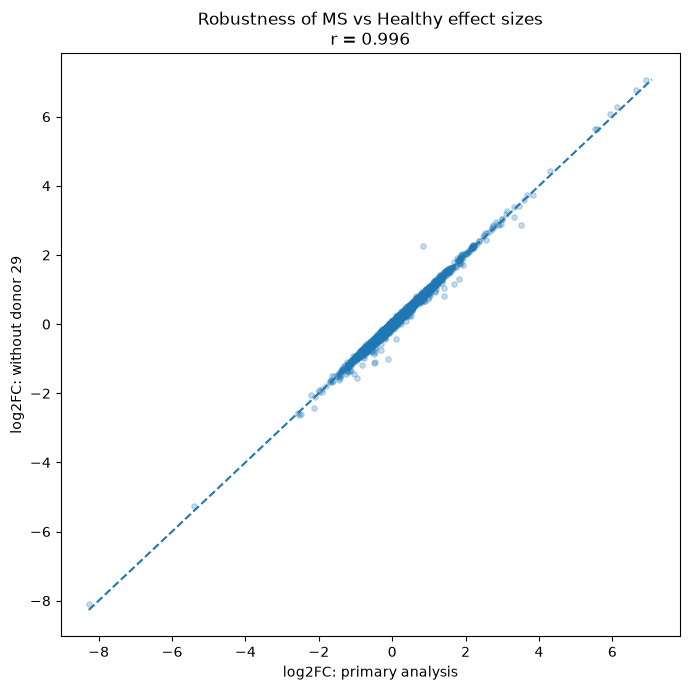

In [9]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 19: Quantify robustness to donor 29
# ============================================================
#
# We now compare effect sizes from:
#
#   PRIMARY analysis      = 10 MS + 3 Healthy
#   SENSITIVITY analysis  =  9 MS + 3 Healthy
#
# The most important question is not simply whether individual
# genes remain below FDR = 0.05.
#
# Instead, we ask:
#
#   1. Are log2 fold changes similar?
#   2. Do genes retain the same direction?
#   3. Do the primary significant genes remain stable?
#
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Combine primary and sensitivity results
# ------------------------------------------------------------

robustness = pd.DataFrame({
    "log2FC_primary":
        de_results["log2FoldChange"],

    "padj_primary":
        de_results["padj"],

    "log2FC_no29":
        de_results_no29["log2FoldChange"],

    "padj_no29":
        de_results_no29["padj"]
})


# ------------------------------------------------------------
# 2. Remove genes without finite LFC estimates
# ------------------------------------------------------------

robustness_clean = robustness[
    np.isfinite(robustness["log2FC_primary"])
    &
    np.isfinite(robustness["log2FC_no29"])
].copy()


# ------------------------------------------------------------
# 3. Correlation across ALL tested genes
# ------------------------------------------------------------

lfc_correlation = robustness_clean[
    ["log2FC_primary", "log2FC_no29"]
].corr().iloc[0, 1]

print(
    "Log2FC correlation across all genes:",
    round(lfc_correlation, 4)
)


# ------------------------------------------------------------
# 4. Identify primary significant genes
# ------------------------------------------------------------

primary_sig = robustness_clean[
    (robustness_clean["padj_primary"] < 0.05)
    &
    (robustness_clean["log2FC_primary"].abs() >= 0.5)
].copy()


# ------------------------------------------------------------
# 5. Check direction agreement
# ------------------------------------------------------------

primary_sig["same_direction"] = (
    np.sign(primary_sig["log2FC_primary"])
    ==
    np.sign(primary_sig["log2FC_no29"])
)


print(
    "\nPrimary significant genes:",
    len(primary_sig)
)

print(
    "Same direction after removing donor 29:",
    primary_sig["same_direction"].sum(),
    "/",
    len(primary_sig)
)


# ------------------------------------------------------------
# 6. Show comparison table
# ------------------------------------------------------------

comparison_table = primary_sig[
    [
        "log2FC_primary",
        "padj_primary",
        "log2FC_no29",
        "padj_no29",
        "same_direction"
    ]
].sort_values("padj_primary")

display(comparison_table)


# ------------------------------------------------------------
# 7. Plot effect-size agreement
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.scatter(
    robustness_clean["log2FC_primary"],
    robustness_clean["log2FC_no29"],
    alpha=0.25,
    s=15
)

# Identity line: identical effect in both analyses
limits = [
    min(
        robustness_clean["log2FC_primary"].min(),
        robustness_clean["log2FC_no29"].min()
    ),
    max(
        robustness_clean["log2FC_primary"].max(),
        robustness_clean["log2FC_no29"].max()
    )
]

plt.plot(
    limits,
    limits,
    linestyle="--"
)

plt.xlabel("log2FC: primary analysis")
plt.ylabel("log2FC: without donor 29")

plt.title(
    f"Robustness of MS vs Healthy effect sizes\n"
    f"r = {lfc_correlation:.3f}"
)

plt.tight_layout()
plt.show()

Significant genes: 15


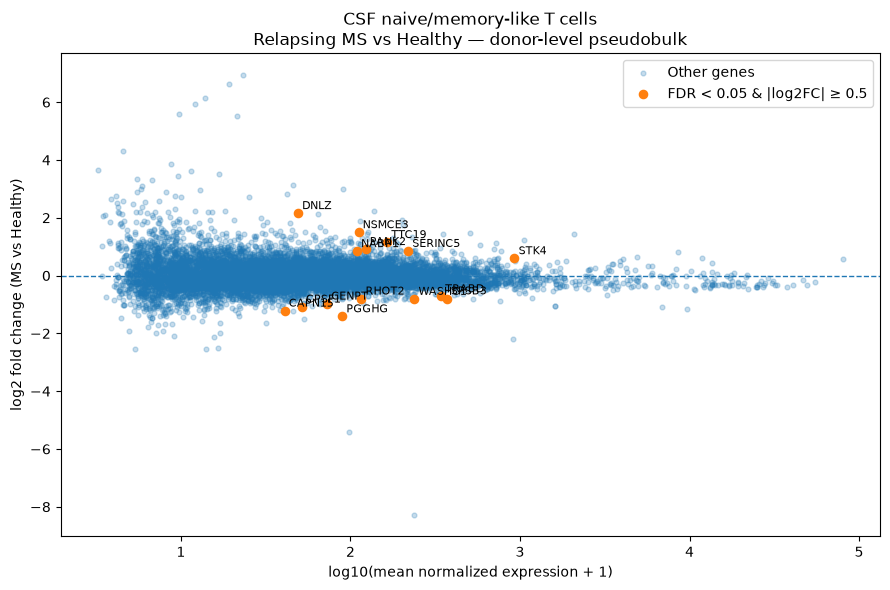


Saved DE results and MA plot.


In [10]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 20: Save DE results and generate MA plot
# ============================================================
#
# The MA plot shows:
#
#   X-axis = average expression (baseMean)
#   Y-axis = MS vs Healthy log2 fold change
#
# Positive log2FC:
#       higher expression in MS
#
# Negative log2FC:
#       lower expression in MS
#
# We highlight genes satisfying:
#
#       FDR < 0.05
#       |log2FC| >= 0.5
#
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Create output directories
# ------------------------------------------------------------

results_dir = Path("../results")
figures_dir = Path("../figures")

results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)


# ------------------------------------------------------------
# 2. Save complete primary DE results
# ------------------------------------------------------------

de_results.to_csv(
    results_dir / "tcell_csf_MS_vs_Healthy_DE_results.csv"
)


# Save sensitivity results
de_results_no29.to_csv(
    results_dir / "tcell_csf_MS_vs_Healthy_DE_results_no_donor29.csv"
)


# Save robustness comparison
comparison_table.to_csv(
    results_dir / "tcell_csf_MS_vs_Healthy_robustness.csv"
)


# ------------------------------------------------------------
# 3. Define significant genes
# ------------------------------------------------------------

sig_mask = (
    (de_results["padj"] < 0.05)
    &
    (de_results["log2FoldChange"].abs() >= 0.5)
)

sig_genes = de_results.loc[sig_mask].copy()


print("Significant genes:", len(sig_genes))


# ------------------------------------------------------------
# 4. Create MA plot
# ------------------------------------------------------------

plot_data = de_results[
    np.isfinite(de_results["baseMean"])
    &
    np.isfinite(de_results["log2FoldChange"])
].copy()


plt.figure(figsize=(9, 6))

# All genes
plt.scatter(
    np.log10(plot_data["baseMean"] + 1),
    plot_data["log2FoldChange"],
    alpha=0.25,
    s=12,
    label="Other genes"
)

# Significant genes
plt.scatter(
    np.log10(sig_genes["baseMean"] + 1),
    sig_genes["log2FoldChange"],
    s=35,
    label="FDR < 0.05 & |log2FC| ≥ 0.5"
)

# No-change line
plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)


# ------------------------------------------------------------
# 5. Label the 15 significant genes
# ------------------------------------------------------------

for gene, row in sig_genes.iterrows():

    plt.annotate(
        gene,
        (
            np.log10(row["baseMean"] + 1),
            row["log2FoldChange"]
        ),
        fontsize=8,
        xytext=(3, 3),
        textcoords="offset points"
    )


plt.xlabel("log10(mean normalized expression + 1)")
plt.ylabel("log2 fold change (MS vs Healthy)")

plt.title(
    "CSF naive/memory-like T cells\n"
    "Relapsing MS vs Healthy — donor-level pseudobulk"
)

plt.legend()

plt.tight_layout()


# ------------------------------------------------------------
# 6. Save figure
# ------------------------------------------------------------

plt.savefig(
    figures_dir / "tcell_csf_MS_vs_Healthy_MA_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nSaved DE results and MA plot.")

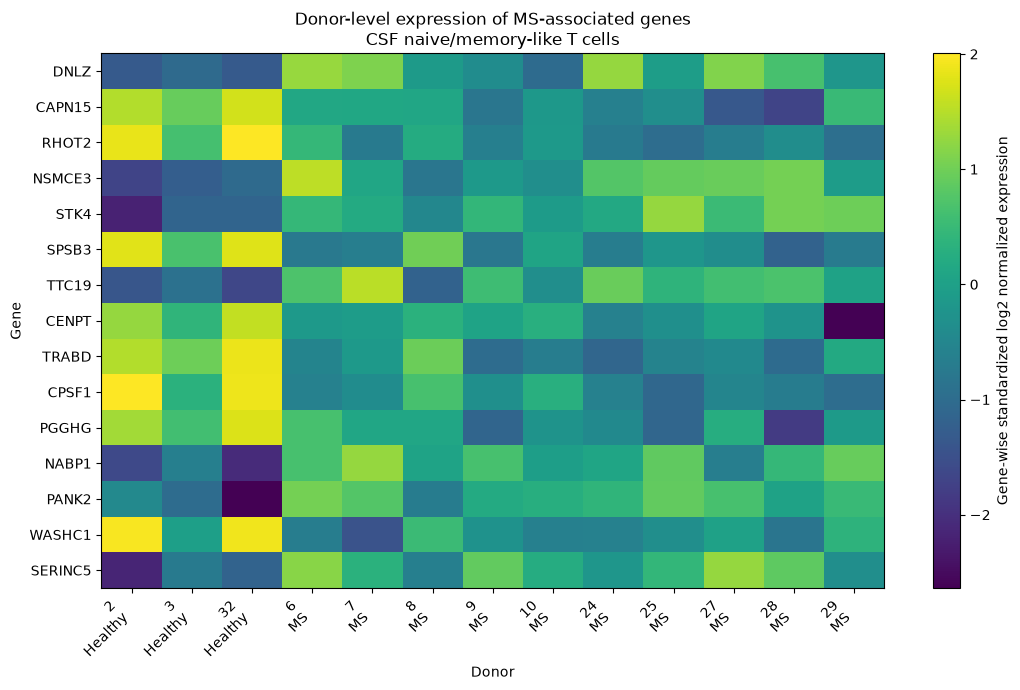

In [11]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 21: Donor-level expression of significant genes
# ============================================================
#
# PURPOSE
# -------
# DESeq2 found 15 genes with:
#
#       FDR < 0.05
#       |log2FC| >= 0.5
#
# Now we inspect their expression across individual donors.
#
# This helps us determine whether the disease-associated
# differences are broadly consistent across donors or are
# driven by only a small number of samples.
#
# IMPORTANT
# ---------
# This visualization does NOT replace the DESeq2 statistical
# model.
#
# DE testing used RAW counts.
# Here we use normalized counts only for visualization.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Obtain DESeq2-normalized counts
# ------------------------------------------------------------

normalized_counts = pd.DataFrame(
    dds.layers["normed_counts"],
    index=deseq_counts.index,
    columns=deseq_counts.columns
)


# ------------------------------------------------------------
# 2. Select our significant genes
# ------------------------------------------------------------

sig_gene_names = sig_genes.index.tolist()

heatmap_data = normalized_counts[
    sig_gene_names
].copy()


# ------------------------------------------------------------
# 3. Log-transform for visualization
# ------------------------------------------------------------

heatmap_log = np.log2(
    heatmap_data + 1
)


# ------------------------------------------------------------
# 4. Z-score each gene across donors
#
# This lets us compare relative expression patterns even
# though different genes have very different absolute counts.
# ------------------------------------------------------------

heatmap_z = (
    heatmap_log - heatmap_log.mean(axis=0)
) / heatmap_log.std(axis=0)


# ------------------------------------------------------------
# 5. Order donors by disease group
# ------------------------------------------------------------

donor_order = (
    deseq_metadata
    .sort_values("disease_status")
    .index
)

heatmap_z = heatmap_z.loc[donor_order]


# ------------------------------------------------------------
# 6. Draw heatmap
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    heatmap_z.T,
    aspect="auto"
)

ax.set_xticks(
    range(len(heatmap_z.index))
)

ax.set_xticklabels(
    [
        f"{donor}\n{deseq_metadata.loc[donor, 'disease_status']}"
        for donor in heatmap_z.index
    ],
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(heatmap_z.columns))
)

ax.set_yticklabels(
    heatmap_z.columns
)

ax.set_xlabel("Donor")
ax.set_ylabel("Gene")

ax.set_title(
    "Donor-level expression of MS-associated genes\n"
    "CSF naive/memory-like T cells"
)

cbar = plt.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Gene-wise standardized log2 normalized expression"
)

plt.tight_layout()


# ------------------------------------------------------------
# 7. Save figure
# ------------------------------------------------------------

plt.savefig(
    "../figures/tcell_csf_MS_vs_Healthy_DE_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Duplicated gene names: 0

Genes available for ranked enrichment: 11371
Highest Wald statistic: 4.350552029212875
Lowest Wald statistic: -5.762513062338249

Top 15 MS-up ranked genes:


,gene,stat
0,STK4,4.350552
1,NSMCE3,4.290504
2,DNLZ,4.186947
3,TTC19,4.152991
4,SERINC5,3.941707
5,NABP1,3.937222
6,PANK2,3.906265
7,KHDRBS1,3.777059
8,PLEKHA3,3.765657
9,CHMP4B,3.754181



Top 15 MS-down ranked genes:


,gene,stat
11356,ADCY3,-3.607417
11357,NRM,-3.643164
11358,ARHGAP45,-3.648507
11359,PPARD,-3.705648
11360,POLRMT,-3.771081
11361,SRSF2,-3.841256
11362,WASHC1,-3.911857
11363,PGGHG,-4.010855
11364,CPSF1,-4.117091
11365,CENPT,-4.163005


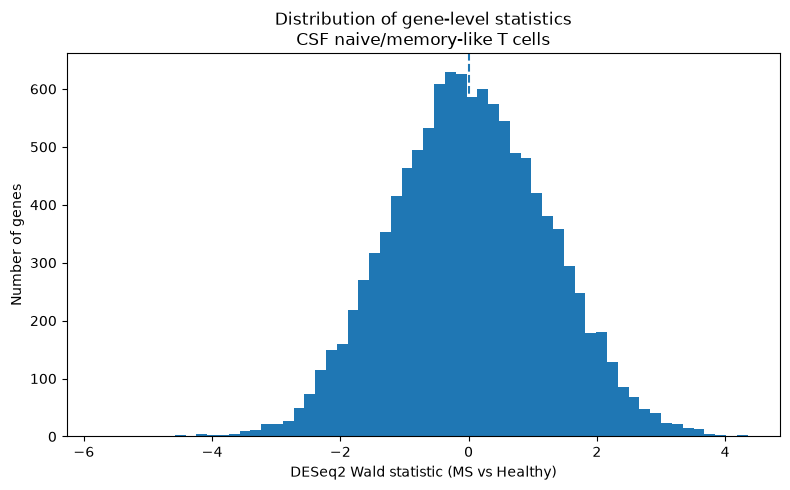


Ranked gene list saved successfully.


In [12]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 22A: Prepare ranked gene list for pathway enrichment
# ============================================================
#
# PURPOSE
# -------
# Instead of performing pathway analysis using only the
# 15 FDR-significant genes, we will use the FULL DE result.
#
# Each gene will be ranked using the DESeq2 Wald statistic:
#
#       positive stat -> tendency toward higher expression in MS
#       negative stat -> tendency toward lower expression in MS
#
# This ranked list can subsequently be used for GSEA-style
# pathway enrichment.
#
# IMPORTANT
# ---------
# This is still the primary analysis containing donor 29.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Extract gene + Wald statistic
# ------------------------------------------------------------

ranked_genes = (
    de_results[["stat"]]
    .copy()
    .reset_index()
)

ranked_genes.columns = [
    "gene",
    "stat"
]


# ------------------------------------------------------------
# 2. Remove missing/non-finite statistics
# ------------------------------------------------------------

ranked_genes = ranked_genes[
    np.isfinite(ranked_genes["stat"])
].copy()


# ------------------------------------------------------------
# 3. Check duplicated gene symbols
# ------------------------------------------------------------

n_duplicates = ranked_genes["gene"].duplicated().sum()

print(
    "Duplicated gene names:",
    n_duplicates
)


# ------------------------------------------------------------
# 4. Sort from strongest MS-up signal to strongest MS-down
# ------------------------------------------------------------

ranked_genes = ranked_genes.sort_values(
    "stat",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. Basic summary
# ------------------------------------------------------------

print(
    "\nGenes available for ranked enrichment:",
    len(ranked_genes)
)

print(
    "Highest Wald statistic:",
    ranked_genes["stat"].max()
)

print(
    "Lowest Wald statistic:",
    ranked_genes["stat"].min()
)


print("\nTop 15 MS-up ranked genes:")
display(
    ranked_genes.head(15)
)


print("\nTop 15 MS-down ranked genes:")
display(
    ranked_genes.tail(15)
)


# ------------------------------------------------------------
# 6. Plot distribution of ranking statistic
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    ranked_genes["stat"],
    bins=60
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "DESeq2 Wald statistic (MS vs Healthy)"
)

plt.ylabel(
    "Number of genes"
)

plt.title(
    "Distribution of gene-level statistics\n"
    "CSF naive/memory-like T cells"
)

plt.tight_layout()

plt.savefig(
    "../figures/tcell_csf_MS_vs_Healthy_Wald_stat_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Save ranked list
# ------------------------------------------------------------

ranked_genes.to_csv(
    "../results/tcell_csf_MS_vs_Healthy_ranked_genes.csv",
    index=False
)

print(
    "\nRanked gene list saved successfully."
)

In [13]:
# ============================================================
# STEP 22B.1
# Check whether GSEApy is available
# ============================================================

try:
    import gseapy as gp

    print("GSEApy is installed.")
    print("Version:", gp.__version__)

except ImportError:
    print("GSEApy is NOT installed.")

GSEApy is NOT installed.


In [14]:
# ============================================================
# Install GSEApy in the current notebook environment
# ============================================================

import sys

!{sys.executable} -m pip install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.0/693.0 kB 15.6 MB/s  0:00:00


In [15]:
import gseapy as gp

print("GSEApy version:", gp.__version__)
print("GSEApy imported successfully.")

GSEApy version: 1.3.1
GSEApy imported successfully.


In [16]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 22B.2: Identify Reactome gene-set library
# ============================================================
#
# GSEApy can retrieve gene-set collections from Enrichr.
# Before running ranked enrichment, we check the currently
# available libraries rather than hard-coding a library name.
# ============================================================

import gseapy as gp


# ------------------------------------------------------------
# 1. Retrieve currently available human gene-set libraries
# ------------------------------------------------------------

libraries = gp.get_library_name(
    organism="Human"
)


# ------------------------------------------------------------
# 2. Find libraries containing "Reactome"
# ------------------------------------------------------------

reactome_libraries = [
    lib for lib in libraries
    if "reactome" in lib.lower()
]


print("Available Reactome libraries:")

for lib in reactome_libraries:
    print(" -", lib)

Available Reactome libraries:
 - Reactome_2022
 - Reactome_Pathways_2024


In [17]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 22B.3: Ranked Reactome pathway enrichment
# ============================================================
#
# BIOLOGICAL QUESTION
# -------------------
# Are Reactome pathways systematically enriched toward the
# MS-up or MS-down end of our donor-level DE ranking?
#
# INPUT
# -----
# All 11,371 genes ranked by the DESeq2 Wald statistic.
#
# Interpretation:
#
#   positive NES -> pathway enriched toward genes higher in MS
#   negative NES -> pathway enriched toward genes lower in MS
#
# We will focus primarily on:
#       NES
#       FDR q-value
#       leading-edge genes
#
# ============================================================

import gseapy as gp
import pandas as pd
from pathlib import Path


# ------------------------------------------------------------
# 1. Prepare ranking in GSEApy format
# ------------------------------------------------------------

gsea_ranking = ranked_genes[
    ["gene", "stat"]
].copy()


# ------------------------------------------------------------
# 2. Run preranked GSEA
# ------------------------------------------------------------

pre_res = gp.prerank(
    rnk=gsea_ranking,
    gene_sets="Reactome_Pathways_2024",

    # Pathway-size restrictions
    min_size=15,
    max_size=500,

    # Permutations for enrichment significance
    permutation_num=1000,

    # Reproducibility
    seed=42,

    # Keep output quiet in notebook
    verbose=True,

    # We will save our own results
    outdir=None
)


# ------------------------------------------------------------
# 3. Extract results
# ------------------------------------------------------------

gsea_results = pre_res.res2d.copy()


print("Number of pathways tested:")
print(len(gsea_results))

print("\nResult columns:")
print(gsea_results.columns.tolist())


# ------------------------------------------------------------
# 4. Convert numerical columns explicitly
# ------------------------------------------------------------

for col in [
    "ES",
    "NES",
    "NOM p-val",
    "FDR q-val",
    "FWER p-val"
]:
    if col in gsea_results.columns:
        gsea_results[col] = pd.to_numeric(
            gsea_results[col],
            errors="coerce"
        )


# ------------------------------------------------------------
# 5. Sort by FDR
# ------------------------------------------------------------

gsea_results = gsea_results.sort_values(
    "FDR q-val"
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. Display top pathways
# ------------------------------------------------------------

print("\nTop 20 Reactome pathways by FDR:")

display(
    gsea_results[
        [
            "Term",
            "NES",
            "NOM p-val",
            "FDR q-val",
            "Lead_genes"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# 7. Count FDR-significant pathways
# ------------------------------------------------------------

significant_pathways = gsea_results[
    gsea_results["FDR q-val"] < 0.05
].copy()


print(
    "\nReactome pathways with FDR < 0.05:",
    len(significant_pathways)
)


# ------------------------------------------------------------
# 8. Separate MS-up and MS-down pathways
# ------------------------------------------------------------

ms_up_pathways = significant_pathways[
    significant_pathways["NES"] > 0
].copy()

ms_down_pathways = significant_pathways[
    significant_pathways["NES"] < 0
].copy()


print(
    "MS-up enriched pathways:",
    len(ms_up_pathways)
)

print(
    "MS-down enriched pathways:",
    len(ms_down_pathways)
)


# ------------------------------------------------------------
# 9. Save complete enrichment results
# ------------------------------------------------------------

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)

gsea_results.to_csv(
    results_dir /
    "tcell_csf_MS_vs_Healthy_Reactome_GSEA.csv",
    index=False
)

print("\nReactome GSEA results saved.")

2026-09-17 09:48:00,785 [INFO] Parsing data files for GSEA.............................
2026-09-17 09:48:01,325 [INFO] Downloading and generating Enrichr library gene sets......
2026-09-17 09:48:01,890 [INFO] 1064 gene_sets have been filtered out when max_size=500 and min_size=15
2026-09-17 09:48:01,891 [INFO] 1041 gene_sets used for further statistical testing.....
2026-09-17 09:48:01,891 [INFO] Start to run GSEA...Might take a while..................
2026-09-17 09:48:19,975 [INFO] Congratulations. GSEApy runs successfully................



Number of pathways tested:
1041

Result columns:
['Name', 'Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val', 'Tag %', 'Gene %', 'Lead_genes']

Top 20 Reactome pathways by FDR:


,Term,NES,NOM p-val,FDR q-val,Lead_genes
0,Eukaryotic Translation Elongation,-2.824455,0.0,0.0,RPS12;EEF2;RPS18;EEF1B2;RPL19;RPL5;RPS3;RPS28;...
1,Peptide Chain Elongation,-2.793540,0.0,0.0,RPS12;EEF2;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;R...
2,SRP-dependent Cotranslational Protein Targetin...,-2.747160,0.0,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;SRP19;RPS28;SRP9;R...
3,Translation,-2.705300,0.0,0.0,EIF3C;RPS12;EEF2;MRPL12;RPS18;SARS2;EEF1B2;RPL...
4,Mitochondrial Translation Termination,-2.640763,0.0,0.0,RPS12;MRPL12;MRPL34;MRPL53;MRPL9;MRPS21;MRPL33...
5,Mitochondrial Translation Initiation,-2.633792,0.0,0.0,RPS12;MRPL12;MRPL34;MRPL53;MRPL9;MRPS21;MRPL33...
6,Selenocysteine Synthesis,-2.632387,0.0,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;RPS21;...
7,Response of EIF2AK4 (GCN2) to Amino Acid Defic...,-2.631478,0.0,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;RPS21;...
8,Viral mRNA Translation,-2.687053,0.0,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;RPS21;...
9,Nonsense Mediated Decay (NMD) Independent of t...,-2.682443,0.0,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;RPS21;...



Reactome pathways with FDR < 0.05: 54
MS-up enriched pathways: 4
MS-down enriched pathways: 50

Reactome GSEA results saved.


In [18]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 22C: Inspect direction and biological themes
# ============================================================
#
# GSEA identified:
#
#       54 Reactome pathways with FDR < 0.05
#        4 enriched toward MS-up genes
#       50 enriched toward MS-down genes
#
# Because Reactome pathways overlap heavily, we should not
# interpret the 54 terms as 54 independent biological effects.
#
# First we inspect the positive and negative pathways
# separately and examine their leading-edge genes.
# ============================================================


# ------------------------------------------------------------
# 1. MS-UP pathways
# ------------------------------------------------------------

ms_up_sorted = (
    significant_pathways[
        significant_pathways["NES"] > 0
    ]
    .sort_values(
        "NES",
        ascending=False
    )
)

print("======================================")
print("MS-UP REACTOME PATHWAYS")
print("======================================")

display(
    ms_up_sorted[
        [
            "Term",
            "NES",
            "FDR q-val",
            "Lead_genes"
        ]
    ]
)


# ------------------------------------------------------------
# 2. MS-DOWN pathways
# ------------------------------------------------------------

ms_down_sorted = (
    significant_pathways[
        significant_pathways["NES"] < 0
    ]
    .sort_values(
        "NES",
        ascending=True
    )
)

print("\n======================================")
print("TOP 20 MS-DOWN REACTOME PATHWAYS")
print("======================================")

display(
    ms_down_sorted[
        [
            "Term",
            "NES",
            "FDR q-val",
            "Lead_genes"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# 3. Show the leading-edge genes clearly for the
#    four MS-up pathways
# ------------------------------------------------------------

print("\n======================================")
print("MS-UP LEADING-EDGE GENES")
print("======================================")

for _, row in ms_up_sorted.iterrows():

    print("\nPATHWAY:")
    print(row["Term"])

    print("NES:", round(row["NES"], 3))
    print("FDR:", row["FDR q-val"])

    print("Leading-edge genes:")
    print(row["Lead_genes"])

MS-UP REACTOME PATHWAYS


,Term,NES,FDR q-val,Lead_genes
46,Beta-catenin Phosphorylation Cascade,2.061983,0.034533,GSK3B;PPP2R5A;CSNK1A1;FRAT1;FRAT2;CTNNB1;PPP2C...
51,FCERI Mediated MAPK Activation,1.937722,0.047952,IGKC;PLCG2;IGKV1-5;MAPK1;FCER1A;MAP2K4;IGKV3-1...
53,RMTs Methylate Histone Arginines,1.910318,0.049615,SMARCD1;ARID1B;SMARCC1;RPS2;SMARCA2;PBRM1;COPR...
52,Signaling by PDGFR in Disease,1.900130,0.049580,STRN;STAT3;STAT1;ETV6;PIK3R1;KANK1;HRAS;GRB2;W...



TOP 20 MS-DOWN REACTOME PATHWAYS


,Term,NES,FDR q-val,Lead_genes
0,Eukaryotic Translation Elongation,-2.824455,0.0,RPS12;EEF2;RPS18;EEF1B2;RPL19;RPL5;RPS3;RPS28;...
1,Peptide Chain Elongation,-2.793540,0.0,RPS12;EEF2;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;R...
2,SRP-dependent Cotranslational Protein Targetin...,-2.747160,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;SRP19;RPS28;SRP9;R...
3,Translation,-2.705300,0.0,EIF3C;RPS12;EEF2;MRPL12;RPS18;SARS2;EEF1B2;RPL...
8,Viral mRNA Translation,-2.687053,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;RPS21;...
9,Nonsense Mediated Decay (NMD) Independent of t...,-2.682443,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;RPS21;...
10,Eukaryotic Translation Termination,-2.661189,0.0,RPS12;RPS18;RPL19;RPL5;RPS3;RPS28;RPLP0;RPS21;...
11,Mitochondrial Translation Elongation,-2.649216,0.0,RPS12;MRPL12;MRPL34;MRPL53;MRPL9;MRPS21;MRPL33...
4,Mitochondrial Translation Termination,-2.640763,0.0,RPS12;MRPL12;MRPL34;MRPL53;MRPL9;MRPS21;MRPL33...
5,Mitochondrial Translation Initiation,-2.633792,0.0,RPS12;MRPL12;MRPL34;MRPL53;MRPL9;MRPS21;MRPL33...



MS-UP LEADING-EDGE GENES

PATHWAY:
Beta-catenin Phosphorylation Cascade
NES: 2.062
FDR: 0.0345330503716115
Leading-edge genes:
GSK3B;PPP2R5A;CSNK1A1;FRAT1;FRAT2;CTNNB1;PPP2CA;PPP2R5E

PATHWAY:
FCERI Mediated MAPK Activation
NES: 1.938
FDR: 0.04795160708743769
Leading-edge genes:
IGKC;PLCG2;IGKV1-5;MAPK1;FCER1A;MAP2K4;IGKV3-11;IGKV3-20;IGHV3-7;HRAS;MAP2K7;GRB2;MAP3K1;JUN;MAPK3

PATHWAY:
RMTs Methylate Histone Arginines
NES: 1.91
FDR: 0.04961483155431529
Leading-edge genes:
SMARCD1;ARID1B;SMARCC1;RPS2;SMARCA2;PBRM1;COPRS;JAK2

PATHWAY:
Signaling by PDGFR in Disease
NES: 1.9
FDR: 0.04957959374781365
Leading-edge genes:
STRN;STAT3;STAT1;ETV6;PIK3R1;KANK1;HRAS;GRB2;WDR48;FIP1L1;PIK3CB


In [19]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 23: Inspect genes driving MS-up pathway enrichment
# ============================================================
#
# WHY?
# ----
# Some MS-up Reactome pathways contain genes that are not
# obviously characteristic of T cells (for example IGKC,
# immunoglobulin variable genes and FCER1A).
#
# Before interpreting these pathways biologically, we check:
#
#   1. Which leading-edge genes are present?
#   2. Their DESeq2 effect sizes
#   3. Their adjusted p-values
#   4. Their average expression
#
# A pathway can be significantly enriched even when many
# individual genes do not reach gene-level FDR significance.
# ============================================================


# ------------------------------------------------------------
# 1. Collect leading-edge genes from MS-up pathways
# ------------------------------------------------------------

up_leading_genes = set()

for genes in ms_up_sorted["Lead_genes"]:

    for gene in str(genes).split(";"):
        up_leading_genes.add(gene)


up_leading_genes = sorted(up_leading_genes)

print(
    "Unique leading-edge genes across MS-up pathways:",
    len(up_leading_genes)
)


# ------------------------------------------------------------
# 2. Extract their DE statistics
# ------------------------------------------------------------

up_driver_table = de_results.loc[
    de_results.index.intersection(up_leading_genes),
    [
        "baseMean",
        "log2FoldChange",
        "stat",
        "pvalue",
        "padj"
    ]
].copy()


# ------------------------------------------------------------
# 3. Sort by Wald statistic
# ------------------------------------------------------------

up_driver_table = up_driver_table.sort_values(
    "stat",
    ascending=False
)


print("\nMS-up pathway-driving genes:")

display(
    up_driver_table.head(50)
)


# ------------------------------------------------------------
# 4. Specifically inspect immunoglobulin / FCER-related genes
# ------------------------------------------------------------

immune_check = [
    gene for gene in up_driver_table.index
    if (
        gene.startswith("IG")
        or gene.startswith("FCER")
        or gene in ["PLCG2"]
    )
]


print("\nImmunoglobulin / FCER-related genes:")

display(
    up_driver_table.loc[immune_check]
)

Unique leading-edge genes across MS-up pathways: 40

MS-up pathway-driving genes:


,baseMean,log2FoldChange,stat,pvalue,padj
STRN,60.447402,1.326884,3.627137,0.000287,0.082602
SMARCD1,83.433234,0.620123,2.974770,0.002932,0.167236
GSK3B,109.077996,0.556913,2.944194,0.003238,0.173941
ARID1B,195.155480,0.868883,2.919020,0.003511,0.176535
IGKC,20.528240,5.526680,2.881766,0.003955,NaN
SMARCC1,168.160899,0.625154,2.830106,0.004653,0.195332
RPS2,8577.735748,0.828365,2.810865,0.004941,0.197269
PLCG2,15.759771,3.522815,2.566610,0.010270,NaN
SMARCA2,211.577873,0.522270,2.503368,0.012302,0.276454
PBRM1,122.520921,0.544433,2.470530,0.013491,0.280653



Immunoglobulin / FCER-related genes:


,baseMean,log2FoldChange,stat,pvalue,padj
IGKC,20.528240,5.526680,2.881766,0.003955,NaN
PLCG2,15.759771,3.522815,2.566610,0.010270,NaN
IGKV1-5,22.364741,6.929693,2.427905,0.015186,NaN
FCER1A,5.758142,2.093639,1.998487,0.045664,NaN
IGKV3-11,12.814684,6.127772,1.964673,0.049452,NaN
IGKV3-20,2.237189,3.670279,1.712574,0.086791,NaN
IGHV3-7,3.543183,4.301588,1.447695,0.147702,NaN


In [20]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 24: Pathway sensitivity analysis without donor 29
# ============================================================
#
# PURPOSE
# -------
# We already showed that gene-level MS-vs-Healthy effect
# sizes were highly stable after excluding donor 29.
#
# Now we ask whether the Reactome pathway-level conclusions
# are also preserved.
#
# We use the Wald statistics from the DESeq2 sensitivity
# analysis and repeat the same preranked GSEA.
# ============================================================

import numpy as np
import pandas as pd
import gseapy as gp


# ------------------------------------------------------------
# 1. Build sensitivity ranked list
# ------------------------------------------------------------

ranked_no29 = (
    de_results_no29[["stat"]]
    .copy()
    .reset_index()
)

ranked_no29.columns = [
    "gene",
    "stat"
]

ranked_no29 = ranked_no29[
    np.isfinite(ranked_no29["stat"])
].copy()

ranked_no29 = ranked_no29.sort_values(
    "stat",
    ascending=False
)


print(
    "Genes in sensitivity ranking:",
    len(ranked_no29)
)


# ------------------------------------------------------------
# 2. Repeat Reactome preranked GSEA
# ------------------------------------------------------------

pre_res_no29 = gp.prerank(
    rnk=ranked_no29,
    gene_sets="Reactome_Pathways_2024",
    min_size=15,
    max_size=500,
    permutation_num=1000,
    seed=42,
    verbose=False,
    outdir=None
)


# ------------------------------------------------------------
# 3. Extract results
# ------------------------------------------------------------

gsea_no29 = pre_res_no29.res2d.copy()

for col in [
    "ES",
    "NES",
    "NOM p-val",
    "FDR q-val"
]:
    gsea_no29[col] = pd.to_numeric(
        gsea_no29[col],
        errors="coerce"
    )


# ------------------------------------------------------------
# 4. Compare pathways present in both analyses
# ------------------------------------------------------------

pathway_comparison = (
    gsea_results[
        ["Term", "NES", "FDR q-val"]
    ]
    .rename(
        columns={
            "NES": "NES_primary",
            "FDR q-val": "FDR_primary"
        }
    )
    .merge(
        gsea_no29[
            ["Term", "NES", "FDR q-val"]
        ].rename(
            columns={
                "NES": "NES_no29",
                "FDR q-val": "FDR_no29"
            }
        ),
        on="Term",
        how="inner"
    )
)


# ------------------------------------------------------------
# 5. NES correlation
# ------------------------------------------------------------

nes_correlation = pathway_comparison[
    ["NES_primary", "NES_no29"]
].corr().iloc[0, 1]


print(
    "\nNES correlation across Reactome pathways:",
    round(nes_correlation, 4)
)


# ------------------------------------------------------------
# 6. Examine the original 54 significant pathways
# ------------------------------------------------------------

primary_sig_terms = set(
    significant_pathways["Term"]
)

primary_pathway_check = pathway_comparison[
    pathway_comparison["Term"].isin(
        primary_sig_terms
    )
].copy()


primary_pathway_check["same_direction"] = (
    np.sign(primary_pathway_check["NES_primary"])
    ==
    np.sign(primary_pathway_check["NES_no29"])
)


print(
    "\nPrimary significant pathways:",
    len(primary_pathway_check)
)

print(
    "Same enrichment direction:",
    primary_pathway_check["same_direction"].sum(),
    "/",
    len(primary_pathway_check)
)


print(
    "Still FDR < 0.05 without donor 29:",
    (
        primary_pathway_check["FDR_no29"]
        < 0.05
    ).sum(),
    "/",
    len(primary_pathway_check)
)


# ------------------------------------------------------------
# 7. Show strongest primary pathways
# ------------------------------------------------------------

display(
    primary_pathway_check
    .sort_values("FDR_primary")
    .head(25)
)


# ------------------------------------------------------------
# 8. Save sensitivity comparison
# ------------------------------------------------------------

pathway_comparison.to_csv(
    "../results/"
    "tcell_csf_MS_vs_Healthy_Reactome_GSEA_robustness.csv",
    index=False
)

Genes in sensitivity ranking: 11371

NES correlation across Reactome pathways: 0.9534

Primary significant pathways: 54
Same enrichment direction: 54 / 54
Still FDR < 0.05 without donor 29: 53 / 54


,Term,NES_primary,FDR_primary,NES_no29,FDR_no29,same_direction
0,Eukaryotic Translation Elongation,-2.824455,0.000000,-2.949955,0.0,True
1,Peptide Chain Elongation,-2.793540,0.000000,-2.962305,0.0,True
2,SRP-dependent Cotranslational Protein Targetin...,-2.747160,0.000000,-2.949329,0.0,True
3,Translation,-2.705300,0.000000,-2.740007,0.0,True
4,Mitochondrial Translation Termination,-2.640763,0.000000,-2.557733,0.0,True
5,Mitochondrial Translation Initiation,-2.633792,0.000000,-2.594566,0.0,True
6,Selenocysteine Synthesis,-2.632387,0.000000,-2.823137,0.0,True
7,Response of EIF2AK4 (GCN2) to Amino Acid Defic...,-2.631478,0.000000,-2.814780,0.0,True
8,Viral mRNA Translation,-2.687053,0.000000,-2.916250,0.0,True
9,Nonsense Mediated Decay (NMD) Independent of t...,-2.682443,0.000000,-2.906839,0.0,True


In [21]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 25A: Inspect all significant Reactome pathways
# ============================================================
#
# PURPOSE
# -------
# Reactome is hierarchical and many of our 54 significant
# pathways describe closely overlapping biological processes.
#
# Before making the final pathway figure, we inspect the full
# significant set so that we can select representative terms
# rather than plotting many redundant pathways.
#
# We show:
#
#   - pathway name
#   - normalized enrichment score (NES)
#   - FDR q-value
#
# Interpretation:
#
#   NES > 0  -> enriched toward MS-up genes
#   NES < 0  -> enriched toward MS-down genes
#
# ============================================================

significant_pathway_summary = (
    significant_pathways[
        [
            "Term",
            "NES",
            "FDR q-val"
        ]
    ]
    .sort_values(
        "NES",
        ascending=True
    )
    .reset_index(drop=True)
)

pd.set_option(
    "display.max_rows",
    100
)

pd.set_option(
    "display.max_colwidth",
    None
)

display(significant_pathway_summary)

,Term,NES,FDR q-val
0,Eukaryotic Translation Elongation,-2.824455,0.000000
1,Peptide Chain Elongation,-2.793540,0.000000
2,SRP-dependent Cotranslational Protein Targeting to Membrane,-2.747160,0.000000
3,Translation,-2.705300,0.000000
4,Viral mRNA Translation,-2.687053,0.000000
5,Nonsense Mediated Decay (NMD) Independent of the Exon Junction Complex (EJC),-2.682443,0.000000
6,Eukaryotic Translation Termination,-2.661189,0.000000
7,Mitochondrial Translation Elongation,-2.649216,0.000000
8,Mitochondrial Translation Termination,-2.640763,0.000000
9,Mitochondrial Translation Initiation,-2.633792,0.000000


Representative pathways:


,Term,NES,FDR q-val
0,Eukaryotic Translation Elongation,-2.824455,0.000000
15,Mitochondrial Translation,-2.617060,0.000000
27,Cellular Response to Starvation,-2.305320,0.000041
24,Formation of ATP by Chemiosmotic Coupling,-2.285813,0.000036
31,rRNA Processing,-2.069303,0.001463
53,RMTs Methylate Histone Arginines,1.910318,0.049615
51,FCERI Mediated MAPK Activation,1.937722,0.047952
46,Beta-catenin Phosphorylation Cascade,2.061983,0.034533


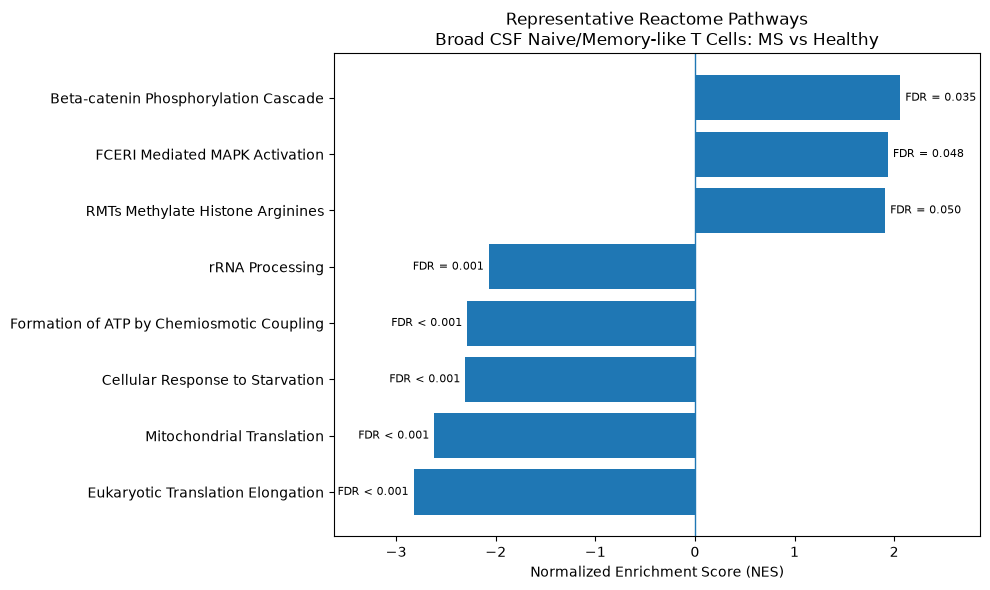


Figure saved to: ../figures/tcell_csf_MS_vs_Healthy_Reactome_GSEA_representative.png


In [22]:
# ============================================================
# PROJECT 1 — BIOLOGICAL ANALYSIS
# STEP 25B: Representative Reactome pathway figure
# ============================================================
#
# PURPOSE
# -------
# The Reactome GSEA returned 54 FDR-significant pathways,
# but many are strongly overlapping.
#
# Instead of plotting all 54 terms, this figure shows a small
# set of representative pathways capturing the major themes.
#
# IMPORTANT:
# This is a visualization choice, NOT a new statistical test.
# The complete enrichment table remains available in results/.
#
# Direction:
#       NES > 0  -> enrichment toward MS-up genes
#       NES < 0  -> enrichment toward MS-down genes
#
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


# ------------------------------------------------------------
# 1. Representative pathways
# ------------------------------------------------------------

representative_terms = [

    # Cytosolic protein synthesis
    "Eukaryotic Translation Elongation",

    # Mitochondrial protein synthesis
    "Mitochondrial Translation",

    # Mitochondrial energy production
    "Formation of ATP by Chemiosmotic Coupling",

    # Ribosome biogenesis
    "rRNA Processing",

    # Nutrient / stress response
    "Cellular Response to Starvation",

    # Positive-enrichment pathways
    "Beta-catenin Phosphorylation Cascade",
    "RMTs Methylate Histone Arginines",
    "FCERI Mediated MAPK Activation",
]


# ------------------------------------------------------------
# 2. Extract pathways from complete GSEA results
# ------------------------------------------------------------

plot_df = (
    gsea_results[
        gsea_results["Term"].isin(
            representative_terms
        )
    ][
        [
            "Term",
            "NES",
            "FDR q-val"
        ]
    ]
    .copy()
)


# Keep pathways in NES order for plotting
plot_df = plot_df.sort_values(
    "NES",
    ascending=True
)


print("Representative pathways:")

display(plot_df)


# ------------------------------------------------------------
# 3. Create horizontal NES plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.barh(
    plot_df["Term"],
    plot_df["NES"]
)


# Zero line separates MS-down and MS-up enrichment
ax.axvline(
    0,
    linewidth=1
)


ax.set_xlabel(
    "Normalized Enrichment Score (NES)"
)

ax.set_ylabel(
    ""
)

ax.set_title(
    "Representative Reactome Pathways\n"
    "Broad CSF Naive/Memory-like T Cells: MS vs Healthy"
)


# ------------------------------------------------------------
# 4. Add FDR values next to bars
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    plot_df.iterrows()
):

    nes = row["NES"]
    fdr = row["FDR q-val"]

    if fdr < 0.001:
        fdr_text = "FDR < 0.001"
    else:
        fdr_text = f"FDR = {fdr:.3f}"

    if nes > 0:
        x_position = nes + 0.05
        alignment = "left"
    else:
        x_position = nes - 0.05
        alignment = "right"

    ax.text(
        x_position,
        i,
        fdr_text,
        va="center",
        ha=alignment,
        fontsize=8
    )


# Give labels enough room
ax.set_xlim(
    plot_df["NES"].min() - 0.8,
    plot_df["NES"].max() + 0.8
)


plt.tight_layout()


# ------------------------------------------------------------
# 5. Save publication-style figure
# ------------------------------------------------------------

figures_dir = Path("../figures")
figures_dir.mkdir(exist_ok=True)

figure_path = (
    figures_dir /
    "tcell_csf_MS_vs_Healthy_Reactome_GSEA_representative.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "\nFigure saved to:",
    figure_path
)